In [1]:
import selenium
import pandas as pd
import glob
import os
import seaborn as sns
import matplotlib.pyplot as plt
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options
import time
from html import unescape
from bs4 import BeautifulSoup
import logging
import random

# Set up logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

# Set up Chrome driver with options
chrome_options = Options()

chrome_options.add_argument("--disable-gpu")

chrome_options.add_argument("--disable-dev-shm-usage")
chrome_options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/136.0.0.0 Safari/537.36")
try:
    driver = webdriver.Chrome(options=chrome_options)
except Exception as e:
    logging.error(f"Erreur lors de l'initialisation du WebDriver: {e}")
    exit(1)
wait = WebDriverWait(driver, 40)

# Define the mapping lists
mapping_lists = {
    "Face": {
        "Primer": ["primer", "pore", "sunburst"],
        "Concealer": ["concealer"],
        "Foundation": ["foundation"],
        "Blush": ["blush", "festive", "cheeky", "use balm", "lip cream"],
        "Highlighter": ["highlighter", "highlighting", "glow stick", "shimmer", "eye pencil"],
        "Setting Spray": ["spray"],
        "Powder": ["powder"],
        "Palette": ["palette"],
        "Contour & Bronzer": ["bronzer", "contour", "tan", "sun", "pen-light", "dark", "nude", "sand", "bronzing"],
    },
    "Eyes": {
        "Eyeliner": ["eyeliner", "liner", "wand"],
        "Eyeshadow": ["eyeshadow", "tone shadow", "jelly", "glitter", "flake"],
        "Eyeshadow Palette": ["palette", "stack"],
        "Mascara": ["mascara"],
        "Eyebrow": ["brow", "eyebrow", "control hair"],
        "Lashes": ["lash", "lashes"],
        "Eye Primer": ["under eye"],
    },
    "Lips": {
        "Lipstick": ["lipstick", "Lip Set", "stacks"],
        "Lip Gloss": ["gloss", "Hydra Jelly", "care", "Mask", "oil", "Soft", "jam"],
        "Lip Liner": ["liner", "marker", "duo"],
        "Lip Balm": ["balm"],
        "Lip Kit": ["kit"],
        "Lip Plumper": ["lip plumper"],
        "Lip Tint": ["lip tint", "Cheek Tint"]
    },
    "Tools & Others": {
        "Brush Set": ["brush set"],
        "Brush": ["brush"],
        "Sponge": ["sponge"],
        "Puff": ["puff"],
        "Makeup Bag": ["bag"],
        "Mirror": ["mirror"],
        "Brush Cleaner": ["cleaner"],
        "Eyelash Tool": ["eyelash"],
        "Eyelash Curler": ["curler"],
        "Brows & Lash Tools": ["mermaid"],
        "Facial Cleaning Tools": ["mattifying"],
        "Eyelashes and Adhesives Kits": ["Magnetizing Eyes"]
    },
    "Hair Tools": {
        "Hair Straightener Iron": ["straightener"],
        "Hot-Air Brushes & Straight Hair Combs": ["sleek", "blowout", "straight-combs"],
        "Curling Tongs & Curling Wands": ["curler", "curling", "curl", "iron"],
    },
    "Hair Care": {
        "Hair Treatment": ["thermal", "glow", "leave-in", "oil"],
        "Hair Coloring": ["dye"],
        "Styling Products": ["Hold"]
    },
}

# Build the final keyword→subcategory map used in matching
subcategory_keywords = {
    cat: {
        kw.lower(): subcat
        for subcat, keywords in mapping_lists[cat].items()
        for kw in keywords
    }
    for cat in mapping_lists
}

data = []
best_seller_products = set()

def extract_image_urls_with_bs4(driver):
    soup = BeautifulSoup(driver.page_source, "html.parser")
    image_urls = []
    try:
        gallery = soup.find("div", class_="fun-pc-std-gallery-thumbnails")
        if gallery:
            img_tags = gallery.find_all("img", class_="fun-pc-image-img")
            for img in img_tags:
                src = img.get("src")
                if src:
                    if src.startswith("//"):
                        src = "https:" + src
                    image_urls.append(src)
        else:
            logging.warning("Galerie d'images non trouvée.")
    except Exception as e:
        logging.error(f"Erreur BeautifulSoup (images): {e}")
    return image_urls

def extract_ingredients_with_bs4(driver):
    soup = BeautifulSoup(driver.page_source, "html.parser")
    ingredients_text = "N/A"
    labels_list = []
    try:
        ingredients_block = soup.find("span", string="Ingredients")
        if ingredients_block:
            container = ingredients_block.find_parent("div", class_="fun-pc-std-collapse-wrapper")
            if container:
                label_divs = container.select(".style_label__chEXT")
                labels_list = [div.get_text(strip=True) for div in label_divs]
                ing_text_block = container.select_one(".fun-pc-ellipsis-wrapper div")
                if ing_text_block:
                    ingredients_text = ing_text_block.get_text(strip=True)
        else:
            logging.warning("Bloc ingrédients non trouvé.")
    except Exception as e:
        logging.error(f"Erreur BeautifulSoup (ingredients): {e}")
    return ingredients_text, labels_list

def click_main_view_more():
    while True:
        try:
            btn = wait.until(EC.element_to_be_clickable((By.CSS_SELECTOR, ".fun-pc-std-list-showMore button")))
            driver.execute_script("arguments[0].click()", btn)
            time.sleep(random.uniform(2, 3))
        except:
            break

def get_product_details(el):
    d = {"Name": "N/A", "Price": "N/A", "Stars": 0.0}
    try:
        d["Name"] = unescape(el.find_element(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-name").text.strip())
    except:
        pass
    try:
        d["Price"] = el.find_element(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-salePrice").text.strip()
    except:
        pass
    try:
        stars = 0.0
        for star in el.find_elements(By.CSS_SELECTOR, ".fun-pc-std-rate-active"):
            pct = star.get_attribute("style").split(":")[1].replace("%", "").replace(";", "")
            stars += int(pct) / 100
        d["Stars"] = stars
    except:
        pass
    return d

def match_nlp_attributes(name, category):
    nm = name.lower()
    for kw, subcat in subcategory_keywords.get(category, {}).items():
        if kw in nm:
            return subcat
    return "N/A"

def get_product_reviews():
    reviews = []
    try:
        # Check if review section exists with a shorter timeout
        review_wait = WebDriverWait(driver, 10)  # Reduced timeout for reviews
        try:
            review_wait.until(EC.presence_of_element_located((By.CSS_SELECTOR, ".fun-pc-sg-review-item-wrapper")))
        except:
            logging.info("Aucune section de reviews trouvée sur cette page.")
            return reviews  # Return empty list if no reviews

        # Scroll to ensure reviews are loaded
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(random.uniform(1, 2))  # Allow JavaScript to render

        html = driver.page_source
        soup = BeautifulSoup(html, 'html.parser')
        review_elements = soup.find_all('div', class_='fun-pc-sg-review-item-wrapper')
        if not review_elements:
            logging.info("Aucun élément de review trouvé via BeautifulSoup.")
            return reviews

        for review_element in review_elements:
            review = {}
            review['username'] = review_element.find('div', class_='fun-pc-sg-review-item-name').text.strip() if review_element.find('div', class_='fun-pc-sg-review-item-name') else "N/A"
            color_section = review_element.find('div', class_='fun-pc-sg-review-item-leftItem', string=lambda text: text and "Color:" in text)
            review['color'] = color_section.find_next('span').text.strip() if color_section else "N/A"
            size_section = review_element.find('div', class_='fun-pc-sg-review-item-leftItem', string=lambda text: text and "Size:" in text)
            review['size'] = size_section.find_next('span').text.strip() if size_section else "N/A"
            review['date'] = review_element.find('div', class_='fun-pc-sg-review-item-date').text.strip() if review_element.find('div', class_='fun-pc-sg-review-item-date') else "N/A"
            review['content'] = review_element.find('div', class_='fun-pc-sg-review-item-content').text.strip() if review_element.find('div', class_='fun-pc-sg-review-item-content') else "N/A"
            stars = len(review_element.find_all('span', class_='fun-pc-std-rate-active')) if review_element.find('span', class_='fun-pc-std-rate-active') else 0
            review['stars'] = stars
            reviews.append(review)
    except Exception as e:
        logging.error(f"Erreur lors de l'extraction des reviews: {e}")
        # Save page source for debugging
        with open(f"error_reviews_{int(time.time())}.html", "w", encoding="utf-8") as f:
            f.write(driver.page_source)
    return reviews

def scrape_category(category_name):
    logging.info(f"Scraping category: {category_name}")
    try:
        wait.until(EC.presence_of_element_located((By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-wrapper")))
        click_main_view_more()
        products = driver.find_elements(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-wrapper")
        for idx, prod in enumerate(products, 1):
            try:
                driver.execute_script("arguments[0].scrollIntoView()", prod)
                time.sleep(0.1)
                details = get_product_details(prod)
                
                product_reviews = []
                image_urls = []
                ingredients_text = "N/A"
                labels_list = []
                original_window = driver.current_window_handle
                for attempt in range(2):  # Retry up to 2 times
                    try:
                        href = prod.find_element(By.TAG_NAME, "a").get_attribute("href")
                        logging.info(f"Tentative d'ouverture: {href}")
                        driver.execute_script("window.open(arguments[0])", href)
                        driver.switch_to.window(driver.window_handles[-1])
                        time.sleep(random.uniform(4, 6))  # Increased delay for page load
                        
                        product_reviews = get_product_reviews()
                        image_urls = extract_image_urls_with_bs4(driver)
                        if category_name not in ["Tools & Others", "Hair Tools"]:
                            ingredients_text, labels_list = extract_ingredients_with_bs4(driver)
                        
                        if category_name == "Hair Tools":
                            try:
                                plug_el = driver.find_element(
                                    By.XPATH,
                                    "//div[contains(@class,'style_mainAttrTitle__OV5Ab')]" +
                                    "/span[contains(text(),'Plug(Voltage):')]/following-sibling::span"
                                )
                                plug = plug_el.text.strip()
                                details["Name"] += f" [{plug}]"
                            except:
                                pass
                        break
                    except Exception as e:
                        logging.error(f"Erreur lors de l'ouverture de la page produit {details['Name']} (essai {attempt+1}): {e}")
                        if attempt == 1:
                            break
                        time.sleep(2)
                    finally:
                        try:
                            driver.close()
                            driver.switch_to.window(original_window)
                        except:
                            logging.warning("Impossible de fermer l'onglet produit.")
                        time.sleep(1)
                
                subcat = match_nlp_attributes(details["Name"], category_name)
                data.append({
                    "Category": category_name,
                    "Name": details["Name"],
                    "Price": details["Price"],
                    "Stars": round(details["Stars"], 1),
                    "Subcategory": subcat,
                    "Best Seller": 0,
                    "Reviews": product_reviews,
                    "Image URLs": image_urls,
                    "Ingredients": ingredients_text,
                    "Labels": labels_list
                })
            except Exception as e:
                logging.error(f"Erreur lors du traitement du produit {idx} dans {category_name}: {e}")
                continue
    except Exception as e:
        logging.error(f"Erreur dans scrape_category {category_name}: {e}")
        with open(f"error_page_{category_name}.html", "w", encoding="utf-8") as f:
            f.write(driver.page_source)
        raise

# Start from homepage with retry logic
for attempt in range(3):
    try:
        driver.get("https://www.sheglam.com/")
        time.sleep(random.uniform(3, 5))
        try:
            cookie_button = wait.until(EC.element_to_be_clickable((By.CSS_SELECTOR, ".cookie-accept-button")))
            cookie_button.click()
        except:
            logging.info("Aucun pop-up de cookies trouvé.")
        break
    except Exception as e:
        logging.error(f"Échec du chargement de la page d'accueil (essai {attempt+1}): {e}")
        if attempt == 2:
            driver.quit()
            exit(1)
        time.sleep(5)

# Click through main categories
main_categories = {
    "Face": "//div[contains(@class,'fun-pc-sheglam-menu-item')]//span[contains(text(),'Face')]",
    "Eyes": "//div[contains(@class,'fun-pc-sheglam-menu-item')]//span[contains(text(),'Eyes')]",
    "Lips": "//div[contains(@class,'fun-pc-sheglam-menu-item')]//span[contains(text(),'Lips')]",
    "Tools & Others": "//div[contains(@class,'fun-pc-sheglam-menu-item')]//span[contains(text(),'Tools')]"
}

for category_name, xpath in main_categories.items():
    try:
        logging.info(f"Tentative de scraping pour {category_name}")
        wait.until(EC.presence_of_element_located((By.XPATH, "//div[contains(@class,'fun-pc-sheglam-menu-item')]")))
        category_btn = wait.until(EC.element_to_be_clickable((By.XPATH, xpath)))
        driver.execute_script("arguments[0].scrollIntoView(true);", category_btn)
        driver.execute_script("arguments[0].click()", category_btn)
        time.sleep(random.uniform(2, 3))
        scrape_category(category_name)
        driver.back()
        time.sleep(random.uniform(2, 3))
        df = pd.DataFrame(data)
        df.to_csv(f"sheglam_{category_name}.csv", index=False)
    except Exception as e:
        logging.error(f"Échec du scraping de {category_name}: {e}")
        continue

# Click on SHEGLAM HAIR tab
try:
    hair_tab = wait.until(EC.element_to_be_clickable(
        (By.XPATH, "//div[contains(@class,'fun-pc-sg-home-tab-tabItem') and contains(text(),'SHEGLAM HAIR')]")
    ))
    driver.execute_script("arguments[0].click()", hair_tab)
    time.sleep(2)
    
    # Click through hair subcategories
    hair_subcategories = {
        "Hair Tools": "//span[contains(@class,'fun-pc-sg-bcc-menu-menuTitle') and contains(text(),'Hot Tools')]",
        "Hair Care": "//span[contains(@class,'fun-pc-sg-bcc-menu-menuTitle') and contains(text(),'Hair Care')]"
    }
    
    for subcat_name, xpath in hair_subcategories.items():
        try:
            subcat_btn = wait.until(EC.element_to_be_clickable((By.XPATH, xpath)))
            driver.execute_script("arguments[0].click()", subcat_btn)
            time.sleep(2)
            scrape_category(subcat_name)
            driver.back()
            time.sleep(2)
        except Exception as e:
            print(f"Failed to scrape {subcat_name}: {str(e)}")
            df = pd.DataFrame(data)
        df.to_csv("sheglam_hair.csv", index=False)
except Exception as e:
    print(f"Failed to navigate to SHEGLAM HAIR: {str(e)}")
    
# Scraping des produits Best Sellers
best_seller_products = set()

try:
    driver.get("https://www.sheglam.com/collection/Best-Sellers-30003?sort=most_popular")
    time.sleep(3)
    click_main_view_more()
    
    product_elements = driver.find_elements(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-wrapper")
    logging.info(f"{len(product_elements)} produits trouvés.")

    for prod in product_elements:
        try:
            name_el = prod.find_element(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-name")
            name = name_el.get_attribute("textContent").strip()
            if name:
                best_seller_products.add(unescape(name.lower()))
        except Exception as e:
            logging.warning(f"Erreur extraction d’un produit : {e}")

except Exception as e:
    logging.error(f"Erreur scraping Best Sellers : {e}")


2025-05-13 14:58:49,532 - INFO - Aucun pop-up de cookies trouvé.
2025-05-13 14:58:49,547 - INFO - Tentative de scraping pour Face
2025-05-13 14:58:52,897 - INFO - Scraping category: Face
2025-05-13 14:59:34,836 - INFO - Tentative d'ouverture: https://www.sheglam.com/product/Pore-No-More-Primer-9934759927465536
2025-05-13 14:59:42,793 - INFO - Tentative d'ouverture: https://www.sheglam.com/product/Good-Grip-Hydrating-Primer-8254238163109
2025-05-13 14:59:50,212 - INFO - Tentative d'ouverture: https://www.sheglam.com/product/Lock'd%C2%A0In%C2%A0Setting%C2%A0Spray-8245628960933
2025-05-13 14:59:59,150 - INFO - Tentative d'ouverture: https://www.sheglam.com/product/Glow-Bloom-Liquid-Highlighter-Vanilla-Frost-7957489483941
2025-05-13 15:00:07,740 - INFO - Tentative d'ouverture: https://www.sheglam.com/product/HydroSlime-Primer-11016389937184832
2025-05-13 15:00:23,972 - INFO - Aucune section de reviews trouvée sur cette page.
2025-05-13 15:00:28,375 - INFO - Tentative d'ouverture: https://w

Failed to navigate to SHEGLAM HAIR: Message: 



In [114]:

best_seller_products = set()

try:
    driver.get("https://www.sheglam.com/collection/Best-Sellers-30003?sort=most_popular")
    time.sleep(3)
    click_main_view_more()
    
    product_elements = driver.find_elements(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-wrapper")
    logging.info(f"{len(product_elements)} produits trouvés.")

    for prod in product_elements:
        try:
            name_el = prod.find_element(By.CSS_SELECTOR, ".fun-pc-sg-goods-cell-name")
            name = name_el.get_attribute("textContent").strip()
            if name:
                best_seller_products.add(unescape(name.lower()))
        except Exception as e:
            logging.warning(f"Erreur extraction d’un produit : {e}")

except Exception as e:
    logging.error(f"Erreur scraping Best Sellers : {e}")

driver.quit()

2025-05-13 18:57:47,336 - INFO - 65 produits trouvés.


In [116]:
best_seller_products

{"adventure time | sheglam be more makeup bag easter mother's day father's day graduation birthday holiday winter y2k fancy fashion makeup cosmetic party beach travel camping outdoors school campus trip festivals decor gift present rose girl cosplay best color charm vibe",
 "adventure time | sheglam full collection set easter mother's day father's day graduation birthday holiday winter y2k fancy fashion makeup cosmetic party beach travel camping outdoors school campus trip festivals decor gift present rose girl cosplay best color charm vibe",
 'all eyes on you eyelash glue liner-black',
 'all-in-one volume & length mascara',
 'baked glow setting powder-translucent',
 'big time eyes volumizing mascara',
 'booster shine plumping lip gloss-own your shine',
 'brows on demand 2-in-1 brow pencil-taupe',
 'buttery bliss blush stick-guava juice',
 'color bloom liquid blush brush',
 'color bloom liquid blush-hot topic',
 'color bloom liquid blush-pink slip',
 'color\xa0bloom\xa0dayglow\xa0liqui

In [128]:
import pandas as pd
bestseller=list(best_seller_products)
fichier = "beauty.csv"
df = pd.read_csv(fichier)
df.columns = df.columns.str.strip()  # Nettoie les noms de colonnes

if 'Name' in df.columns and 'Best Seller' in df.columns:
    # Nettoie les noms pour comparaison
    best_seller_set = {name.strip().lower() for name in bestseller}
    df['Best Seller'] = df['Name'].apply(lambda x: 1 if str(x).strip().lower() in best_seller_set else 0)
    
    print("✅ Mise à jour réussie.")
else:
    print("❌ Colonnes 'Name' ou 'Best Seller' absentes :", df.columns.tolist())
print(df)
df.to_csv('productbeauty.csv', index=False)



✅ Mise à jour réussie.
           Category                                               Name  \
0              Face                                Pore No More Primer   
1              Face                         Good Grip Hydrating Primer   
2              Face                            Lock'd In Setting Spray   
3              Face        Glow Bloom Liquid Highlighter-Vanilla Frost   
4              Face                                  HydroSlime Primer   
..              ...                                                ...   
268  Tools & Others                  Multi-Faceted Makeup Sponge-Green   
269  Tools & Others               Rick and Morty X SHEGLAM Hand Mirror   
270  Tools & Others  Magnetizing Eyes Full & Fabulous Lash + Liner Set   
271  Tools & Others                 Multi-Faceted Makeup Sponge-Forest   
272  Tools & Others   So Long Fallout Mermaid Eyeshadow Shield-Mermaid   

         Price  Stars                   Subcategory  Best Seller  \
0    MX$156.94    4.

In [126]:
fichier = "sheglam_hair.csv"
df = pd.read_csv(fichier)
df.columns = df.columns.str.strip()  # Nettoie les noms de colonnes

if 'Name' in df.columns and 'Best Seller' in df.columns:
    # Nettoie les noms pour comparaison
    best_seller_set = {name.strip().lower() for name in bestseller}
    df['Best Seller'] = df['Name'].apply(lambda x: 1 if str(x).strip().lower() in best_seller_set else 0)
    
    print("✅ Mise à jour réussie.")
else:
    print("❌ Colonnes 'Name' ou 'Best Seller' absentes :", df.columns.tolist())
df.to_csv('producthair.csv', index=False)

✅ Mise à jour réussie.


In [515]:
import pandas as pd

# Supposons que les fichiers s'appellent hair_data.csv et face_data.csv
df_hair = pd.read_csv('producthair.csv') # Adaptez si c'est un autre format ou séparateur
df_face = pd.read_csv('productbeauty.csv')

In [517]:
print(f"Nb de lignes avant doublons (Hair): {len(df_hair)}")
df_hair = df_hair.drop_duplicates()
print(f"Nb de lignes après suppression doublons (Hair): {len(df_hair)}")

print(f"Nb de lignes avant doublons (Face): {len(df_face)}")
df_face = df_face.drop_duplicates()
print(f"Nb de lignes après suppression doublons (Face): {len(df_face)}")

Nb de lignes avant doublons (Hair): 23
Nb de lignes après suppression doublons (Hair): 23
Nb de lignes avant doublons (Face): 273
Nb de lignes après suppression doublons (Face): 273


In [525]:
# Pour Hair
df_hair['Price'] = (
    df_hair['Price']
    .str.replace(r"[^\d.,]", "", regex=True)  
    .str.replace(",", "")                    
    .astype(float)
)

# Pour Face
df_face['Price'] = (
    df_face['Price']
    .str.replace(r"[^\d.,]", "", regex=True)  
    .str.replace(",", "")                    
    .astype(float)
)


In [527]:
cols_to_drop_hair = ['Ingredients', 'Labels']
df_hair = df_hair.drop(columns=cols_to_drop_hair, errors='ignore') # errors='ignore' pour ne pas planter si une colonne n'existe pas
print("Colonnes du DataFrame Hair après suppression:", df_hair.columns.tolist())

Colonnes du DataFrame Hair après suppression: ['Category', 'Name', 'Price', 'Stars', 'Subcategory', 'Best Seller', 'Image URLs']


In [529]:
import pandas as pd
import ast

# Fonction pour parser une chaîne contenant des reviews
def parse_review_string(review_str):
    if pd.isna(review_str):
        return {'avg_score': None, 'nb_reviews': 0, 'all_texts': [], 'all_scores': []}
    try:
        # Convertir la chaîne en structure Python (liste ou dict)
        data = ast.literal_eval(review_str)

        # Cas : liste de reviews
        if isinstance(data, list) and data:
            scores = [r.get('score') for r in data if isinstance(r, dict) and r.get('score') is not None]
            texts = [r.get('text') for r in data if isinstance(r, dict) and r.get('text')]

            avg_score = sum(scores) / len(scores) if scores else 0
            nb_reviews = len(data)

            return {
                'avg_score': avg_score,
                'nb_reviews': nb_reviews,
                'all_texts': texts,
                'all_scores': scores
            }

        # Cas : un seul review sous forme de dictionnaire
        elif isinstance(data, dict) and data:
            score = data.get('score')
            return {
                'avg_score': score,
                'nb_reviews': 1,
                'all_texts': [data.get('text')] if data.get('text') else [],
                'all_scores': [score] if score is not None else []
            }

        else:
            return {'avg_score': None, 'nb_reviews': 0, 'all_texts': [], 'all_scores': []}

    except (SyntaxError, ValueError, TypeError):
        return {'avg_score': None, 'nb_reviews': 0, 'all_texts': [], 'all_scores': []}

# ----------- Application au DataFrame -----------

# Supposons que df_face existe déjà avec une colonne 'Reviews'
# Appliquer le parsing
reviews_parsed = df_face['Reviews'].apply(parse_review_string)

# Extraire les colonnes nécessaires
df_face['Avg_Review_Score'] = reviews_parsed.apply(lambda x: x['avg_score']).fillna(-1)
df_face['Nb_Reviews'] = reviews_parsed.apply(lambda x: x['nb_reviews'])

# Texte résumé (exclut les noms, juste nombre et score)
df_face['Review_Text_Summary'] = df_face.apply(
    lambda row: 'Aucun review' if row['Nb_Reviews'] == 0 else f"{row['Nb_Reviews']} reviews, score moyen {row['Avg_Review_Score']:.1f}",
    axis=1
)

# (Optionnel) Stocker les textes des reviews si nécessaire
# df_face['Review_Texts'] = reviews_parsed.apply(lambda x: x['all_texts'])

# (Optionnel) Supprimer la colonne d'origine
#df_face.drop(columns=['Reviews'], inplace=True)

# Afficher les premières lignes
print(df_face.head())


  Category                                         Name   Price  Stars  \
0     Face                          Pore No More Primer  156.94    4.8   
1     Face                   Good Grip Hydrating Primer  196.23    4.9   
2     Face                      Lock'd In Setting Spray  127.48    4.8   
3     Face  Glow Bloom Liquid Highlighter-Vanilla Frost  117.66    4.7   
4     Face                            HydroSlime Primer  166.76    0.0   

     Subcategory  Best Seller  \
0         Primer            1   
1         Primer            1   
2  Setting Spray            0   
3    Highlighter            1   
4         Primer            1   

                                             Reviews  \
0  [{'username': 's***m', 'color': 'N/A', 'size':...   
1  [{'username': 's***5', 'color': 'N/A', 'size':...   
2  [{'username': 'd***7', 'color': 'N/A', 'size':...   
3  [{'username': 'm***2', 'color': 'N/A', 'size':...   
4                                                 []   

                   

In [531]:
import pandas as pd
import re

def parse_ingredients(list_str):
    if pd.isna(list_str) or list_str.strip() == "":
        return ["Non mentionné"]

    # Supprimer le préfixe "ingredients:" (insensible à la casse, avec ou sans espace)
    list_str = re.sub(r'^ingredients\s*:\s*', '', list_str, flags=re.IGNORECASE)

    # Split sur virgules non échappées
    raw_elements = re.split(r'(?<!\\),', list_str)

    cleaned = []
    seen = set()

    for elem in raw_elements:
        # Nettoyage : échappement \, → virgule réelle
        elem = elem.replace('\\,', ',').strip()

        # Synonymes séparés par / : on garde seulement le premier
        if '/' in elem:
            elem = elem.split('/')[0].strip()

        # Éviter doublons (insensibles à la casse)
        if elem and elem.lower() not in seen:
            cleaned.append(elem)
            seen.add(elem.lower())

    return cleaned if cleaned else ["Non mentionné"]

# Application
df_face['Ingredients_List'] = df_face['Ingredients'].apply(parse_ingredients)


In [533]:
df_face

,Category,Name,Price,Stars,Subcategory,Best Seller,Reviews,Image URLs,Ingredients,Labels,Avg_Review_Score,Nb_Reviews,Review_Text_Summary,Ingredients_List
0,Face,Pore No More Primer,156.94,4.8,Primer,1,"[{'username': 's***m', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,"INGREDIENTS: DIMETHICONE, WATER/AQUA/EAU, PEG-...","['Alcohol-Free', 'Vegan', 'Fragrance-Free', 'G...",0.0,5,"5 reviews, score moyen 0.0","[DIMETHICONE, WATER, PEG-10 DIMETHICONE, ISONO..."
1,Face,Good Grip Hydrating Primer,196.23,4.9,Primer,1,"[{'username': 's***5', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,"INGREDIENTS: WATER/AQUA/EAU, ALOE BARBADENSIS ...","['Vegan', 'Silicone-Free', 'Paraben-Free', 'Ta...",0.0,5,"5 reviews, score moyen 0.0","[WATER, ALOE BARBADENSIS LEAF WATER, ALCOHOL, ..."
2,Face,Lock'd In Setting Spray,127.48,4.8,Setting Spray,0,"[{'username': 'd***7', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,"INGREDIENTS: AQUA/WATER/EAU, POLYESTER-5, VP/V...","['Alcohol-Free', 'Vegan', 'Gluten-Free', 'Para...",0.0,5,"5 reviews, score moyen 0.0","[AQUA, POLYESTER-5, VP, SORBITOL, PROPANEDIOL,..."
3,Face,Glow Bloom Liquid Highlighter-Vanilla Frost,117.66,4.7,Highlighter,1,"[{'username': 'm***2', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,"INGREDIENTS: ISODODECANE, SYNTHETIC FLUORPHLOG...","['Alcohol-Free', 'Vegan', 'Fragrance-Free', 'G...",0.0,5,"5 reviews, score moyen 0.0","[ISODODECANE, SYNTHETIC FLUORPHLOGOPITE, HYDRO..."
4,Face,HydroSlime Primer,166.76,0.0,Primer,1,[],['https://img.ltwebstatic.com/v4/j/pi/2025/04/...,"WATER/AQUA/EAU, GLYCERIN, BUTYLENE GLYCOL, PRO...",[],-1.0,0,Aucun review,"[WATER, GLYCERIN, BUTYLENE GLYCOL, PROPANEDIOL..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,Tools & Others,Multi-Faceted Makeup Sponge-Green,39.09,5.0,Sponge,0,"[{'username': 'С***в', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,NaN,[],0.0,5,"5 reviews, score moyen 0.0",[Non mentionné]
269,Tools & Others,Rick and Morty X SHEGLAM Hand Mirror,114.73,5.0,Mirror,0,"[{'username': 'H***z', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,NaN,[],0.0,1,"1 reviews, score moyen 0.0",[Non mentionné]
270,Tools & Others,Magnetizing Eyes Full & Fabulous Lash + Liner Set,147.12,0.0,Eyelashes and Adhesives Kits,0,[],['https://img.ltwebstatic.com/images3_pi/2024/...,NaN,[],-1.0,0,Aucun review,[Non mentionné]
271,Tools & Others,Multi-Faceted Makeup Sponge-Forest,68.55,4.8,Sponge,0,"[{'username': 'C***z', 'color': 'N/A', 'size':...",['https://img.ltwebstatic.com/images3_pi/2024/...,NaN,[],0.0,5,"5 reviews, score moyen 0.0",[Non mentionné]


In [541]:
def parse_labels(label_str):
    if pd.isna(label_str) or label_str.strip() in ["", "[]"]:
        return []
    try:
        return ast.literal_eval(label_str)
    except:
        return []

df_face['Labels_List'] = df_face['Labels'].apply(parse_labels)

# Étape 2: Transformer les listes en texte formaté comme les ingrédients
df_face['Labels_Text'] = df_face['Labels_List'].apply(lambda x: ', '.join(label.upper() for label in x if isinstance(label, str)))

# Remplacer les vides par 'NON MENTIONNÉ' si tu veux
df_face['Labels_Text'] = df_face['Labels_Text'].replace('', 'NON MENTIONNÉ')
# Sauvegarder dans un fichier Excel
df_hair.to_excel("hair.xlsx", index=False)  # index=False pour ne pas inclure la colonne d'index

df_face.to_excel("beauty.xlsx", index=False)  # index=False pour ne pas inclure la colonne d'index




In [244]:
print("Description des données beauty:")
print(df_face[['Price', 'Stars', 'Avg_Review_Score', 'Nb_Reviews']].describe())
print("\nDescription des données Hair:")
print(df_hair[['Price', 'Stars']].describe())

Description des données Face:
            Price       Stars  Avg_Review_Score  Nb_Reviews
count  273.000000  273.000000        273.000000  273.000000
mean   132.913004    3.616484         -0.241758    3.164835
std     75.215750    2.060086          0.428935    2.179097
min     35.160000    0.000000         -1.000000    0.000000
25%     98.020000    4.000000          0.000000    1.000000
50%    117.660000    4.700000          0.000000    5.000000
75%    156.940000    4.900000          0.000000    5.000000
max    706.930000    5.000000          0.000000    5.000000

Description des données Hair:
            Price      Stars
count   23.000000  23.000000
mean   141.997391   3.439130
std     33.221521   2.328624
min     58.730000   0.000000
25%    117.660000   0.000000
50%    147.120000   5.000000
75%    161.850000   5.000000
max    196.230000   5.000000


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2022114529.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_face, y='Category', order=df_face['Category'].value_counts().index, palette=sheglam_palette)
C:\Users\user\AppData\Local\Temp\ipykernel_26676\2022114529.py:12: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.countplot(data=df_face, y='Category', order=df_face['Category'].value_counts().index, palette=sheglam_palette)


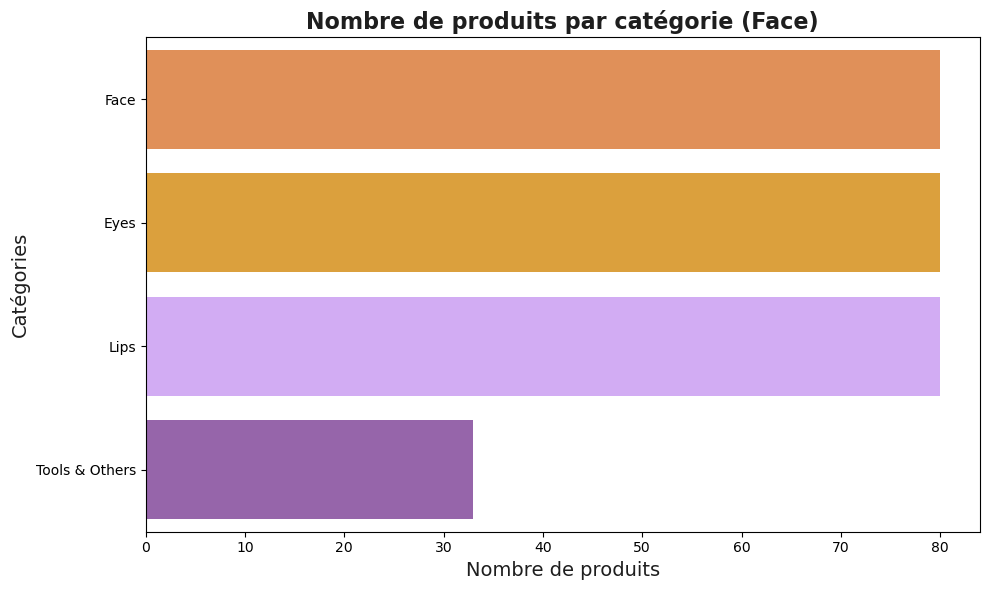

C:\Users\user\AppData\Local\Temp\ipykernel_26676\2022114529.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_face, x='Category', y='Price', palette=sheglam_palette)
C:\Users\user\AppData\Local\Temp\ipykernel_26676\2022114529.py:21: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.boxplot(data=df_face, x='Category', y='Price', palette=sheglam_palette)


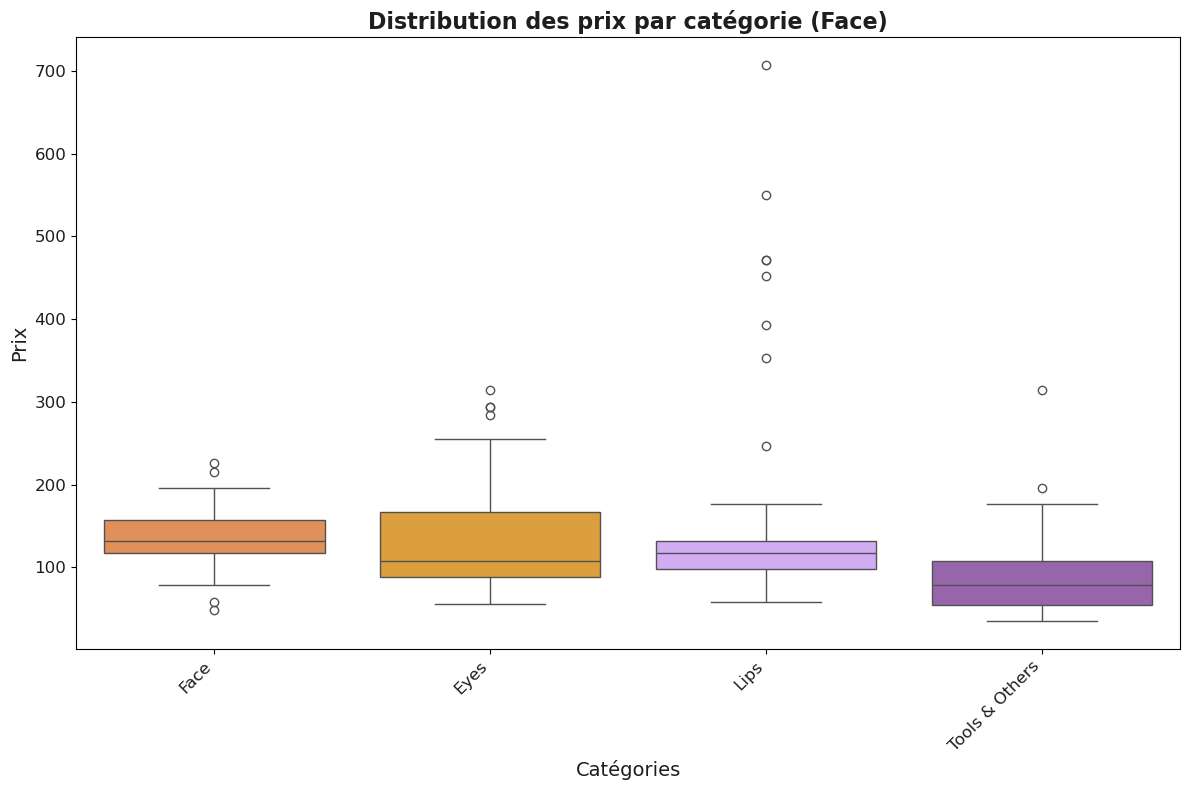

In [246]:
import matplotlib.pyplot as plt
import seaborn as sns

# Définir les couleurs dans le style Sheglam (exemple de couleurs adaptées)
sheglam_palette = ['#F78C42', '#F5A623', '#D3A0FF', '#9B59B6', '#1E1E1E']

# Appliquer les couleurs du thème Sheglam
sns.set_palette(sheglam_palette)

# Premier graphique : Nombre de produits par catégorie
plt.figure(figsize=(10, 6))
sns.countplot(data=df_face, y='Category', order=df_face['Category'].value_counts().index, palette=sheglam_palette)
plt.title('Nombre de produits par catégorie (Face)', fontsize=16, fontweight='bold', color='#1E1E1E')
plt.xlabel('Nombre de produits', fontsize=14, color='#1E1E1E')
plt.ylabel('Catégories', fontsize=14, color='#1E1E1E')
plt.tight_layout()
plt.show()

# Deuxième graphique : Distribution des prix par catégorie
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_face, x='Category', y='Price', palette=sheglam_palette)
plt.title('Distribution des prix par catégorie (Face)', fontsize=16, fontweight='bold', color='#1E1E1E')
plt.xticks(rotation=45, ha='right', fontsize=12, color='#1E1E1E')
plt.yticks(fontsize=12, color='#1E1E1E')
plt.xlabel('Catégories', fontsize=14, color='#1E1E1E')
plt.ylabel('Prix', fontsize=14, color='#1E1E1E')
plt.tight_layout()
plt.show()



Top 20 Ingrédients les plus fréquents:
[('DIMETHICONE', 84), ('SILICA', 81), ('SYNTHETIC WAX', 76), ('PHENOXYETHANOL', 69), ('CAPRYLIC', 61), ('WATER', 56), ('SYNTHETIC FLUORPHLOGOPITE', 54), ('MICA', 52), ('CAPRYLYL GLYCOL', 51), ('ISONONYL ISONONANOATE', 49), ('DIISOSTEARYL MALATE', 44), ('BUTYLENE GLYCOL', 42), ('HYDROGENATED POLYISOBUTENE', 40), ('ETHYLHEXYL PALMITATE', 39), ('ETHYLHEXYLGLYCERIN', 38), ('TRIDECYL TRIMELLITATE', 38), ('HYDROGENATED STYRENE', 38), ('GLYCERIN', 36), ('TRIMETHYLSILOXYSILICATE', 35), ('BIS-DIGLYCERYL POLYACYLADIPATE-2', 33)]

Top 20 Labels les plus fréquents:
[('Clean', 214), ('Phthalates-Free', 214), ('Sulfates-Free', 211), ('Gluten-Free', 208), ('Paraben-Free', 197), ('Vegan', 194), ('Alcohol-Free', 187), ('Talc-Free', 170), ('Fragrance-Free', 154), ('Mineral Oil Free', 91), ('Silicone-Free', 55), ('Non-Acnegenic', 1), ('Dematologist Tested', 1)]


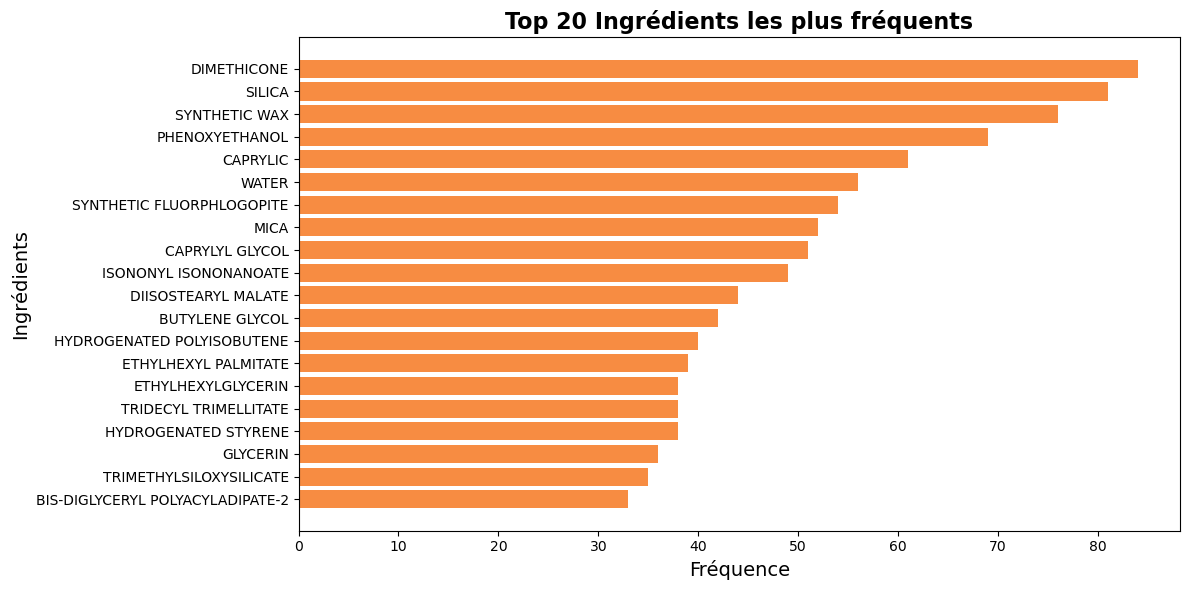

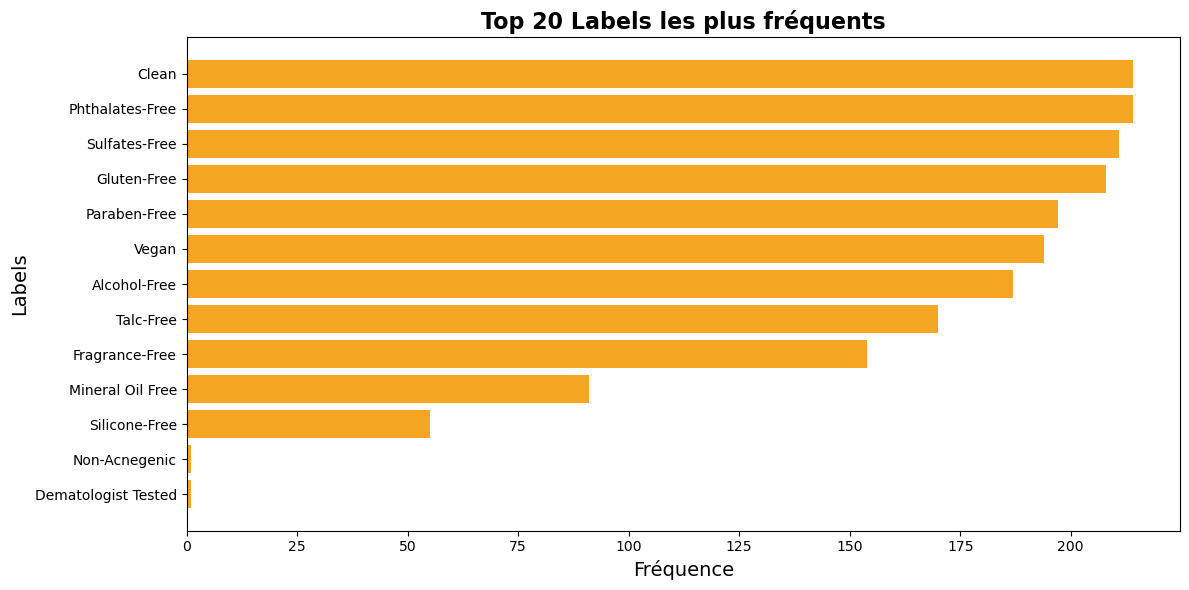

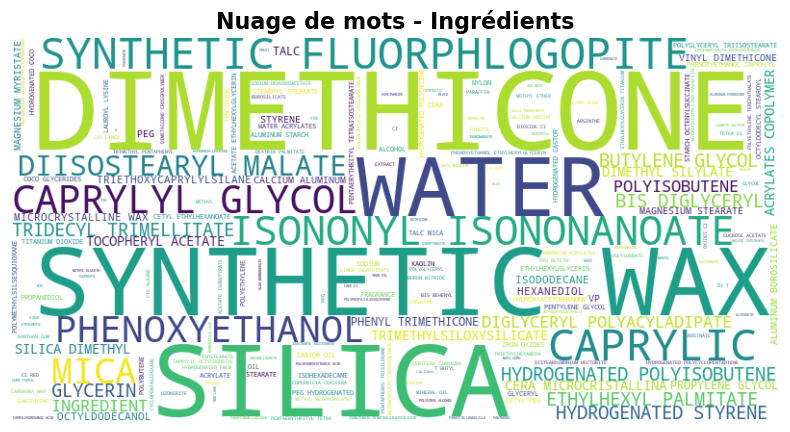

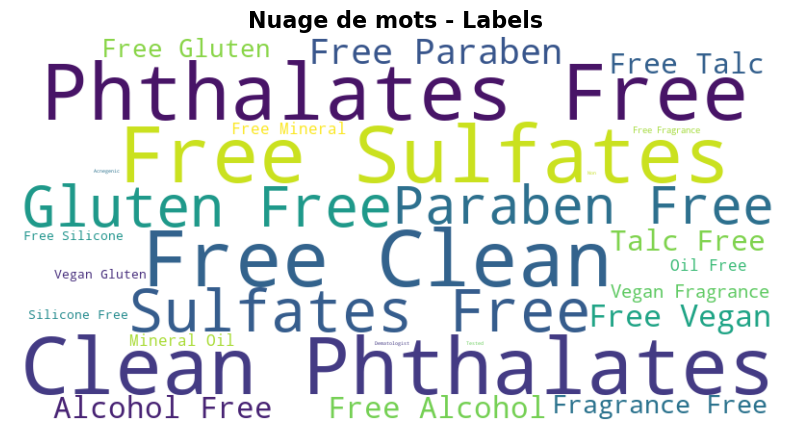

In [304]:
import itertools
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Filtrer "Non mentionné"
df_face_filtered_ingredients = df_face[df_face['Ingredients_List'].apply(lambda x: 'Non mentionné' not in x)]
df_face_filtered_labels = df_face[df_face['Labels_List'].apply(lambda x: 'Non mentionné' not in x)]

# Aplatir les listes
all_ingredients = list(itertools.chain.from_iterable(df_face_filtered_ingredients['Ingredients_List']))
all_labels = list(itertools.chain.from_iterable(df_face_filtered_labels['Labels_List']))

# Compter les occurrences
ingredient_counts = Counter(all_ingredients)
label_counts = Counter(all_labels)

# Affichage top 20
print("\nTop 20 Ingrédients les plus fréquents:")
print(ingredient_counts.most_common(20))

print("\nTop 20 Labels les plus fréquents:")
print(label_counts.most_common(20))

# ------------------- Visualisations ------------------- #

# Barplot - Ingrédients
top_20_ingredients = ingredient_counts.most_common(20)
ingredients, counts = zip(*top_20_ingredients)

plt.figure(figsize=(12, 6))
plt.barh(ingredients, counts, color='#F78C42')  # orange Sheglam
plt.title('Top 20 Ingrédients les plus fréquents', fontsize=16, fontweight='bold')
plt.xlabel('Fréquence', fontsize=14)
plt.ylabel('Ingrédients', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Barplot - Labels
top_20_labels = label_counts.most_common(20)
labels, label_counts_values = zip(*top_20_labels)

plt.figure(figsize=(12, 6))
plt.barh(labels, label_counts_values, color='#F5A623')  # jaune Sheglam
plt.title('Top 20 Labels les plus fréquents', fontsize=16, fontweight='bold')
plt.xlabel('Fréquence', fontsize=14)
plt.ylabel('Labels', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Wordcloud - Ingrédients
ingredients_text = " ".join(all_ingredients)
wordcloud_ingredients = WordCloud(width=800, height=400, background_color='white').generate(ingredients_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_ingredients, interpolation='bilinear')
plt.axis('off')
plt.title('Nuage de mots - Ingrédients', fontsize=16, fontweight='bold')
plt.show()

# Wordcloud - Labels
labels_text = " ".join(all_labels)
wordcloud_labels = WordCloud(width=800, height=400, background_color='white').generate(labels_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_labels, interpolation='bilinear')
plt.axis('off')
plt.title('Nuage de mots - Labels', fontsize=16, fontweight='bold')
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_26676\4214067788.py:57: FutureWarning:



The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.




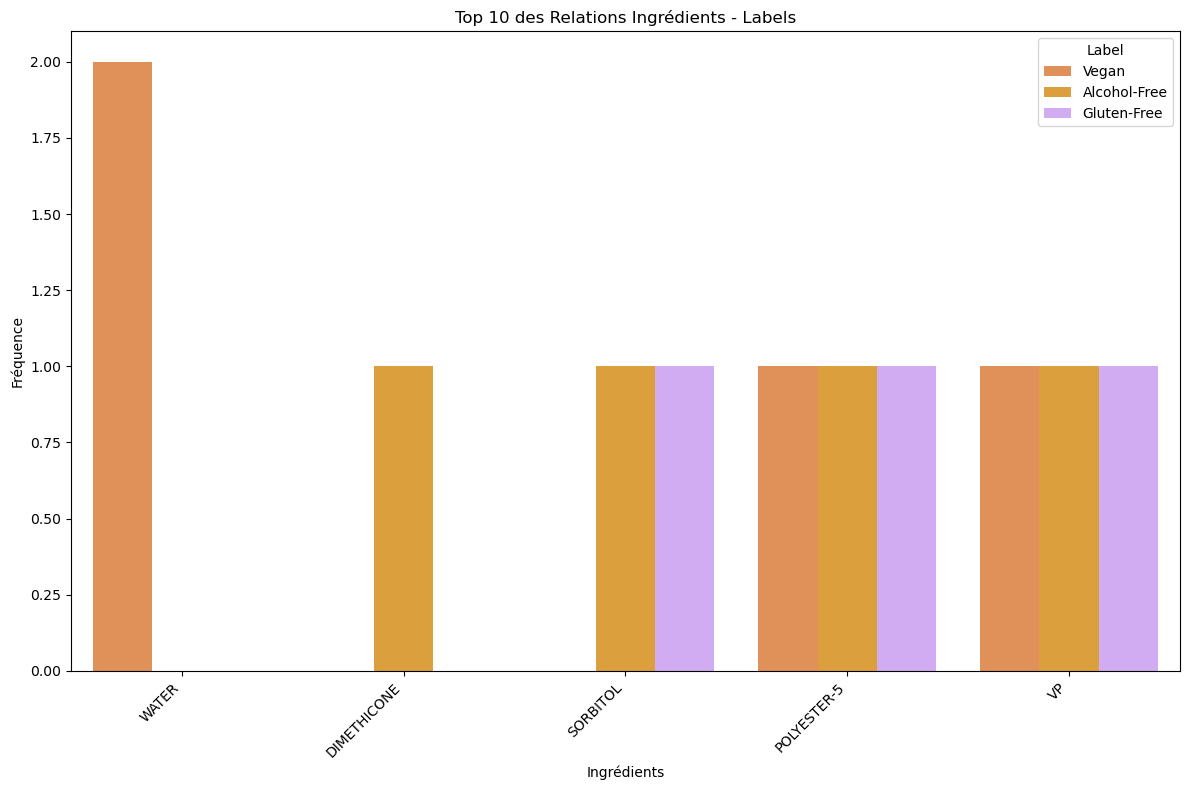

In [441]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Charger le DataFrame (assurez-vous d'avoir chargé votre propre DataFrame ici)
# df = pd.read_csv("mon_fichier.csv") ← à activer si tu utilises un fichier CSV

# Exemple de DataFrame df_face (remplace par ton propre DataFrame)
df_face = pd.DataFrame({
    'Ingredients_List': [
        ['DIMETHICONE', 'WATER', 'PEG-10 DIMETHICONE', 'ISONONYL ISONONATE'],
        ['WATER', 'ALOE BARBADENSIS LEAF WATER', 'ALCOHOL'],
        ['AQUA', 'POLYESTER-5', 'VP', 'SORBITOL'],
        ['ISODODECANE', 'SYNTHETIC FLUORPHLOGOPITE', 'HYDROGENATED LECITHIN']
    ],
    'Labels_List': [
        ['Alcohol-Free', 'Vegan', 'Fragrance-Free'],
        ['Vegan', 'Silicone-Free', 'Paraben-Free'],
        ['Alcohol-Free', 'Vegan', 'Gluten-Free'],
        ['Alcohol-Free', 'Vegan', 'Fragrance-Free']
    ]
})

# Nettoyer : on exclut les lignes avec "Non mentionné" et les valeurs nulles
df_valid = df_face[
    df_face['Ingredients_List'].notnull() & df_face['Labels_List'].notnull() &
    (~df_face['Ingredients_List'].apply(lambda x: any('Non mentionné' in s for s in x))) &
    (~df_face['Labels_List'].apply(lambda x: any('Non mentionné' in s for s in x)))
]

# Dictionnaire pour compter les relations ingrédient → labels
ingredient_to_labels = defaultdict(lambda: defaultdict(int))

# Parcourir chaque ligne et créer le dictionnaire des relations
for _, row in df_valid.iterrows():
    ingredients = [i.strip().upper() for i in row['Ingredients_List'] if isinstance(i, str)]
    labels = [l.strip() for l in row['Labels_List'] if isinstance(l, str)]
    
    for ingredient in ingredients:
        for label in labels:
            ingredient_to_labels[ingredient][label] += 1

# Créer un DataFrame avec les relations ingrédient → labels et leurs fréquences
ingredient_labels_data = []
for ingredient, label_counts in ingredient_to_labels.items():
    for label, count in label_counts.items():
        ingredient_labels_data.append([ingredient, label, count])

df_ingredient_labels = pd.DataFrame(ingredient_labels_data, columns=["Ingrédient", "Label", "Fréquence"])

# Trier par la fréquence et prendre les 10 premières relations les plus fréquentes
top_ingredient_labels = df_ingredient_labels.sort_values(by="Fréquence", ascending=False).head(10)

# Tracer un graphique en barres pour les 10 relations les plus fréquentes
plt.figure(figsize=(12, 8))
sns.barplot(x="Ingrédient", y="Fréquence", hue="Label", data=top_ingredient_labels, ci=None)

# Ajouter des titres et ajuster les labels
plt.title("Top 10 des Relations Ingrédients - Labels")
plt.xlabel("Ingrédients")
plt.ylabel("Fréquence")
plt.xticks(rotation=45, ha="right")  # Rotation des étiquettes pour plus de lisibilité
plt.tight_layout()

# Affichage du graphique
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_26676\3587977131.py:28: UserWarning:

Glyph 127775 (\N{GLOWING STAR}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 127775 (\N{GLOWING STAR}) missing from current font.



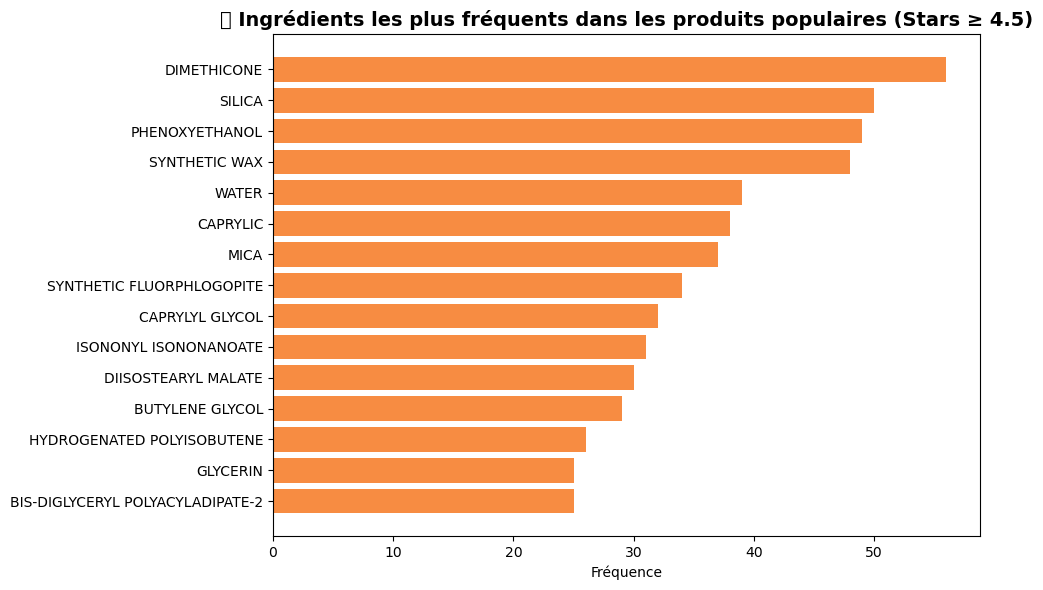

C:\Users\user\AppData\Local\Temp\ipykernel_26676\3587977131.py:37: UserWarning:

Glyph 127991 (\N{LABEL}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 127991 (\N{LABEL}) missing from current font.



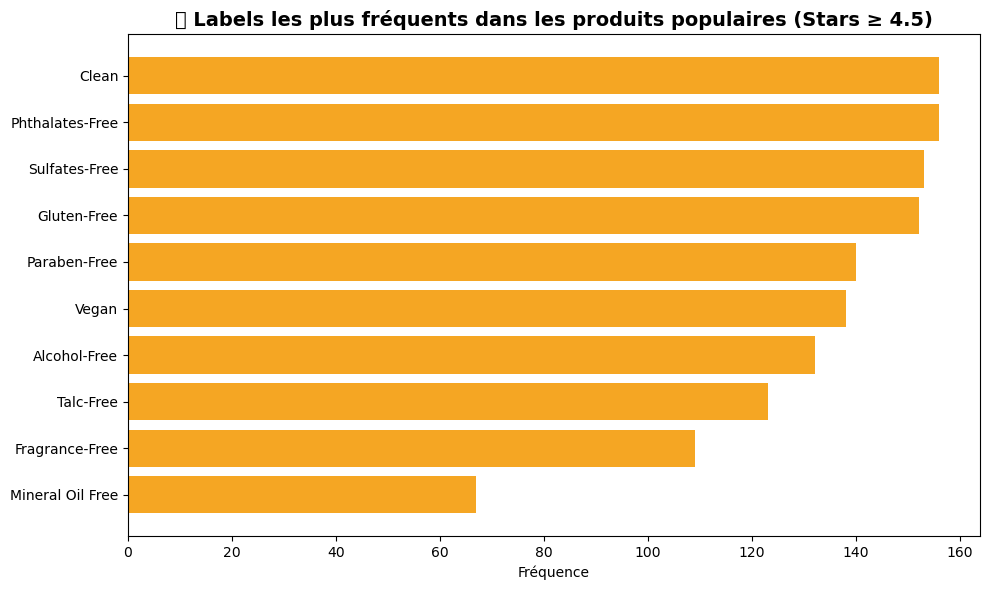

In [332]:
# Produits populaires
top_products = df_face[df_face['Stars'] >= 4.5]

# Aplatir les ingrédients
import itertools
from collections import Counter

top_ingredients = list(itertools.chain.from_iterable(top_products['Ingredients_List']))
top_ingredients = [ing for ing in top_ingredients if ing != "Non mentionné"]
top_ingredient_counts = Counter(top_ingredients).most_common(15)

labels_top = list(itertools.chain.from_iterable(top_products['Labels_List']))
labels_top = [lab for lab in labels_top if lab != "Non mentionné"]
label_counts_top = Counter(labels_top).most_common(10)
df_face_filtered_labels = df_face[df_face['Labels_List'].apply(lambda x: 'Non mentionné' not in x)]
all_labels = list(itertools.chain.from_iterable(df_face_filtered_labels['Labels_List']))
labels_text = " ".join(all_labels)
import matplotlib.pyplot as plt

# Déballage des ingrédients
ingredients, counts = zip(*top_ingredient_counts)

plt.figure(figsize=(10, 6))
plt.barh(ingredients, counts, color='#F78C42')  # Couleur Sheglam inspirée
plt.title("🌟 Ingrédients les plus fréquents dans les produits populaires (Stars ≥ 4.5)", fontsize=14, fontweight='bold')
plt.xlabel("Fréquence")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
labels, counts = zip(*label_counts_top)

plt.figure(figsize=(10, 6))
plt.barh(labels, counts, color='#F5A623')  # Couleur jaune Sheglam
plt.title("🏷️ Labels les plus fréquents dans les produits populaires (Stars ≥ 4.5)", fontsize=14, fontweight='bold')
plt.xlabel("Fréquence")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



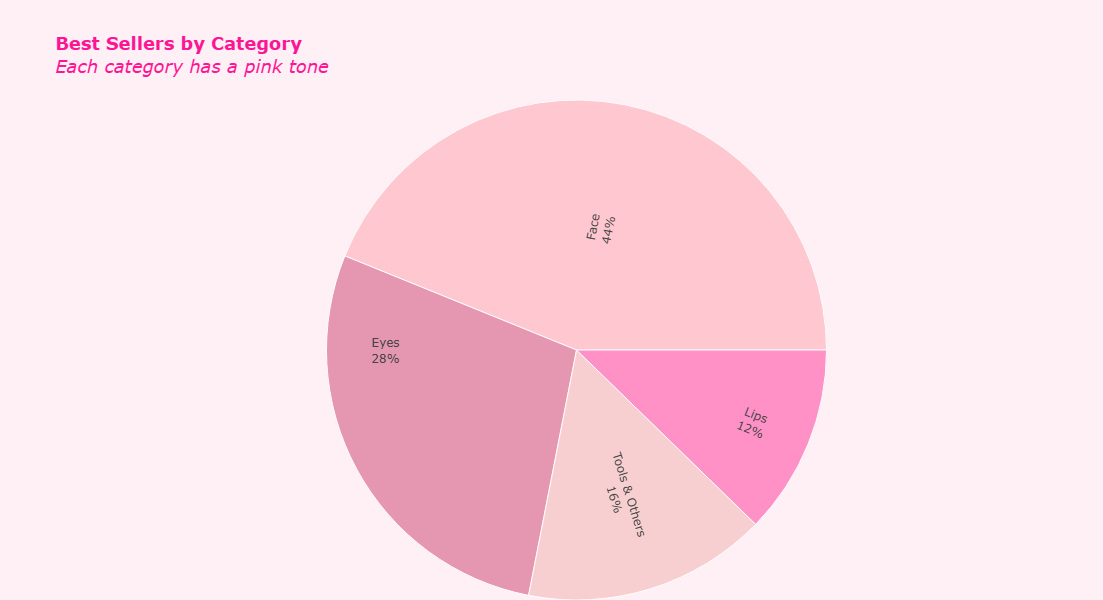

In [320]:
# Interactive sunburst chart showing the number of best-selling products by category,
import plotly.express as px
best_sellers = df_face[df_face['Best Seller'] == 1]
best_sellers_cat = best_sellers['Category'].value_counts().reset_index()
best_sellers_cat.columns = ['Category', 'Count']
color_map = {
    'Face': '#FFB6C1',
    'Lips': '#FF69B4',
    'Eyes': '#DB7093',
    'Tools & Others': '#F4C2C2'}
fig = px.sunburst(
    best_sellers_cat,
    path=['Category'],
    values='Count',
    color='Category',
    color_discrete_map=color_map,
    title='<b>Best Sellers by Category</b><br><i>Each category has a pink tone</i>')
fig.update_traces(
    marker=dict(line=dict(color='white', width=1)),
    hovertemplate='<b>%{label}</b><br>Best Sellers: %{value}<extra></extra>',
    textinfo='label+percent entry',
    insidetextorientation='radial')
fig.update_layout(
    paper_bgcolor='#FFF0F5',
    margin=dict(t=100, l=50, r=0, b=0),
    height=600,
    width=800,
    title_font=dict(size=18, color='#FF1493'),
    uniformtext=dict(minsize=8, mode='hide'),
    clickmode='event+select')
fig.show()

In [318]:
import re
# Define the new collection names as listed
collection_patterns = [
    r'Adventure\s*Time',
    r'Harry\s*Potter\s*\|\s*SHEGLAM\s*2\.0',
    r'Harley\s*Quinn',
    r'Rick\s*and\s*Morty',
    r'Crimson\s*Butterfly',
    r'Hello\s*Kitty\s*\|\s*SHEGLAM',
    r'The\s*Powerpuff\s*Girls',
    r'Ember\s*Rose',
    r'Cosmic\s*Come\s*Up',
    r'Harry\s*Potter\s*\|\s*SHEGLAM\s*1\.0',
    r'Chroma\s*Zone\s*2\.0',
    r'Care\s*Bears',
    r'Corpse\s*Bride',
    r'Marilyn\s*Monroe',
    r'Frida\s*Kahlo',
    r'Willy\s*Wonka'
]
# Combine into a single regex pattern (case-insensitive)
combined_pattern = re.compile('|'.join(collection_patterns), re.IGNORECASE)
# Filter rows where 'Name' contains a collection name
collections_df = df_face[df_face['Name'].str.contains(combined_pattern, na=False)].copy()
collections_df['collections'] = collections_df['Name'].str.extract(f"({combined_pattern.pattern})", flags=re.IGNORECASE)
# Select relevant columns
collections_df = collections_df[['collections', 'Name', 'Price', 'Best Seller']]
collections_df.reset_index(drop=True, inplace=True)
collections_df.head()

,collections,Name,Price,Best Seller
0,Rick and Morty,Rick and Morty X SHEGLAM Pickle Rick Setting S...,147.12,1
1,The Powerpuff Girls,The Powerpuff Girls X SHEGLAM Tough Love Shimm...,107.84,0
2,Adventure Time,Adventure Time | SHEGLAM Bubbline Cream Blush ...,147.12,0
3,Rick and Morty,Rick and Morty X SHEGLAM Mr. Sanchez Cream Blush,147.12,0
4,Marilyn Monroe,Marilyn Monroe X SHEGLAM Color Bloom Dewy Liqu...,156.94,0


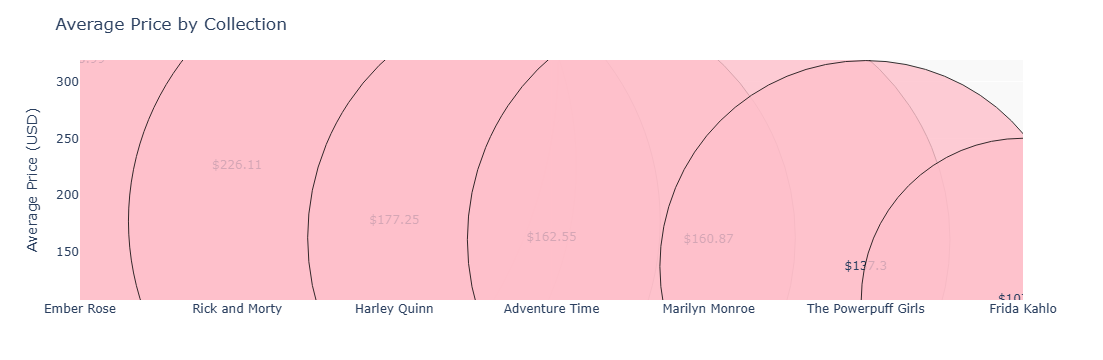

In [322]:
import plotly.graph_objects as go
avg_price = (collections_df.groupby('collections')['Price']
             .mean()
             .round(2)
             .sort_values(ascending=False)
             .reset_index())
# Create the figure
fig = go.Figure()
# Add floating bubbles
for _, row in avg_price.iterrows():
    fig.add_trace(go.Scatter(
        x=[row['collections']],
        y=[row['Price']],
        mode='markers+text',
        marker=dict(
            size=row['Price'] * 3,  
            color='pink',  
            opacity=0.8,
            line=dict(width=1, color='black')  
        ),
        text=[f"${row['Price']}"],
        textposition='middle center',
        showlegend=False))
# Layout adjustments
fig.update_layout(
    title='Average Price by Collection',
    yaxis=dict(title='Average Price (USD)'),
    xaxis=dict(title=None),
    plot_bgcolor='#f9f9f9',
    margin=dict(t=60, b=60),)
# Show the plot
fig.show()

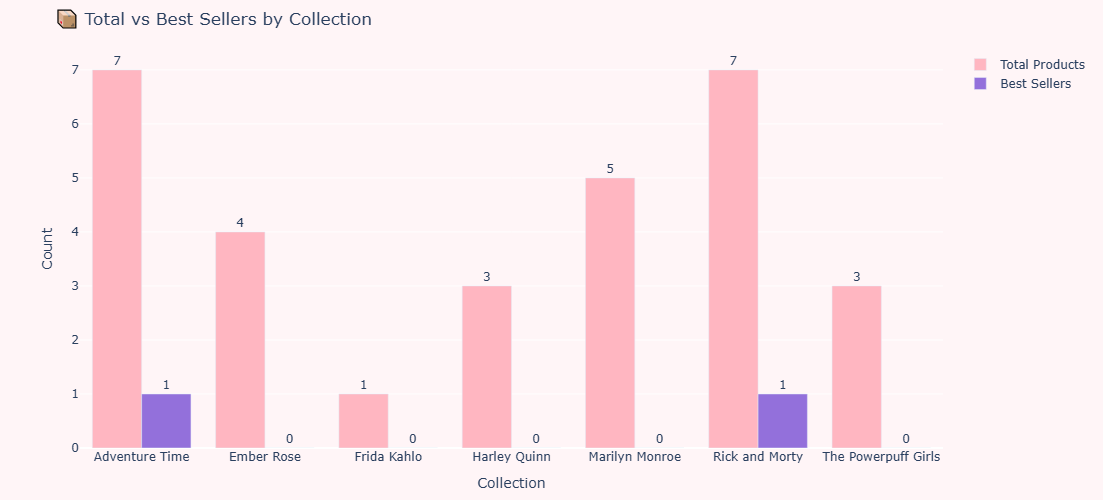

In [324]:
summary = collections_df.groupby('collections')['Best Seller'].agg(
    Total='count',
    Best='sum'
).reset_index()
fig = go.Figure(data=[
    go.Bar(
        x=summary['collections'],
        y=summary['Total'],
        name='Total Products',
        marker_color='#FFB6C1',
        text=summary['Total'],
        textposition='outside'
    ),
    go.Bar(
        x=summary['collections'],
        y=summary['Best'],
        name='Best Sellers',
        marker_color='#9370DB',
        text=summary['Best'],
        textposition='outside'
    )])
fig.update_layout(
    title="📦 Total vs Best Sellers by Collection",
    barmode='group',
    xaxis_title='Collection',
    yaxis_title='Count',
    plot_bgcolor='#FFF5F7',
    paper_bgcolor='#FFF5F7',
    height=500,
    margin=dict(t=50, b=50))
fig.show()

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



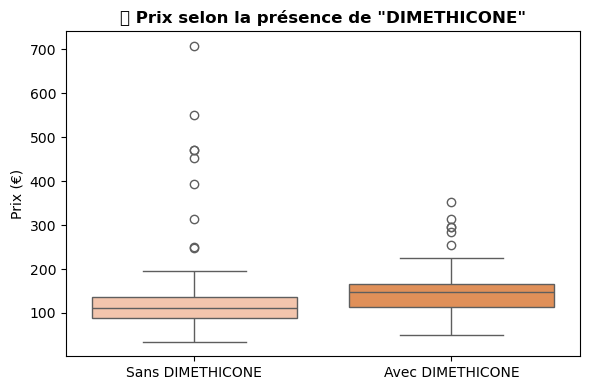

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



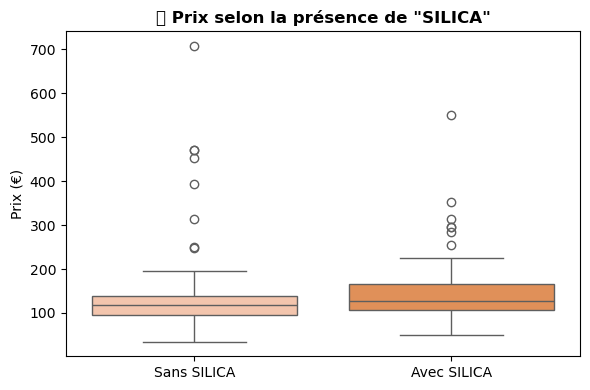

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



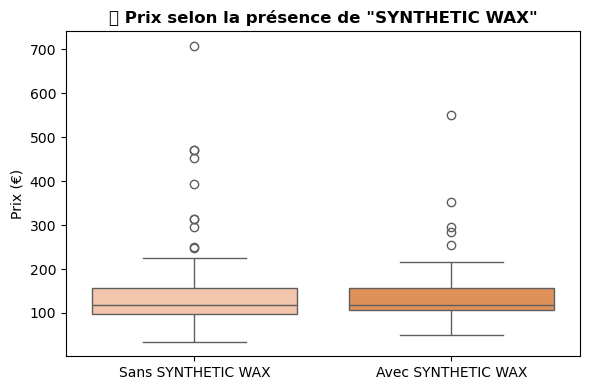

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



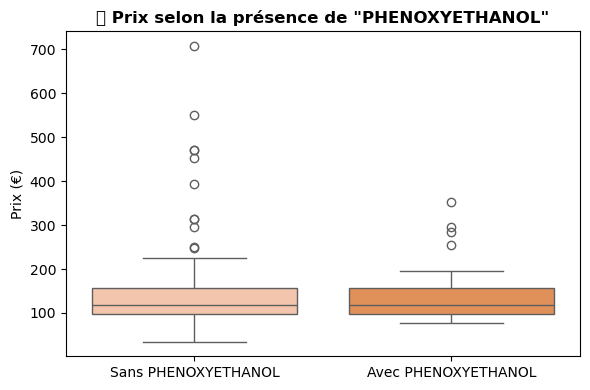

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



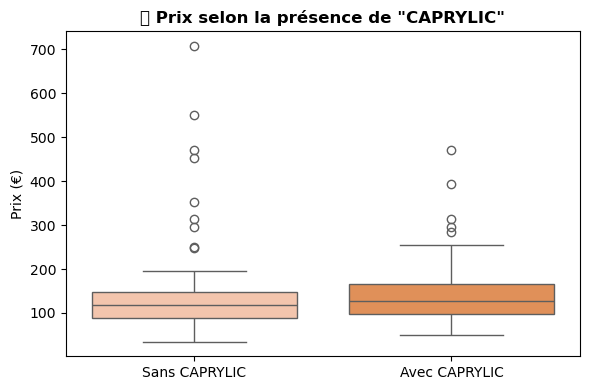

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



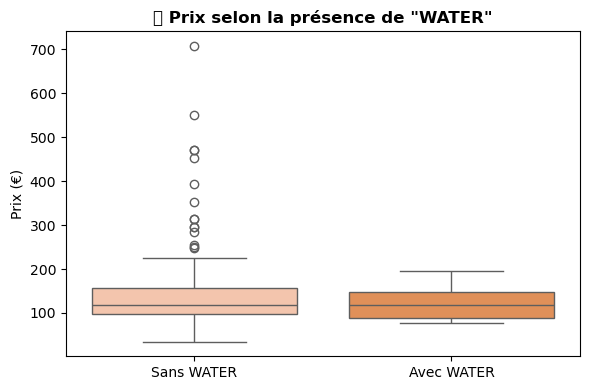

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



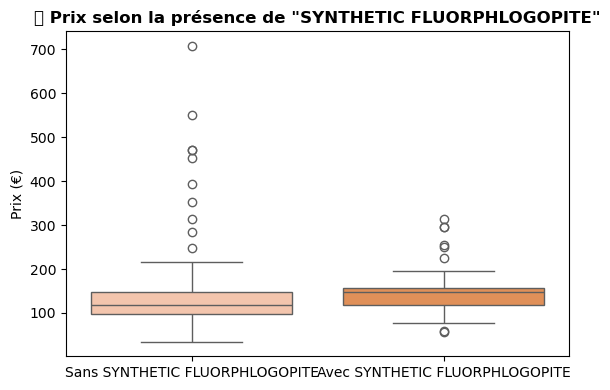

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



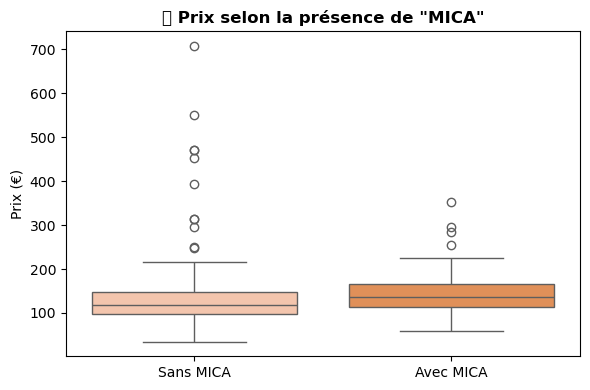

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



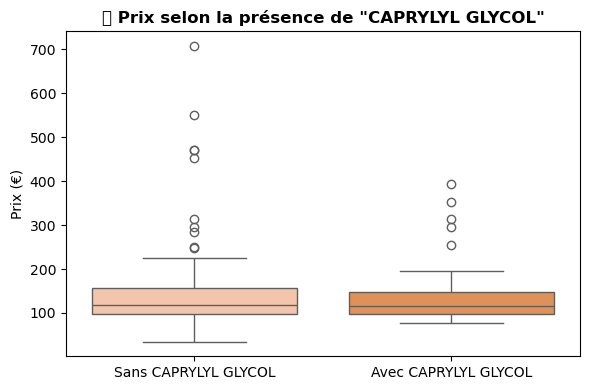

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\1205294519.py:34: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128176 (\N{MONEY BAG}) missing from current font.



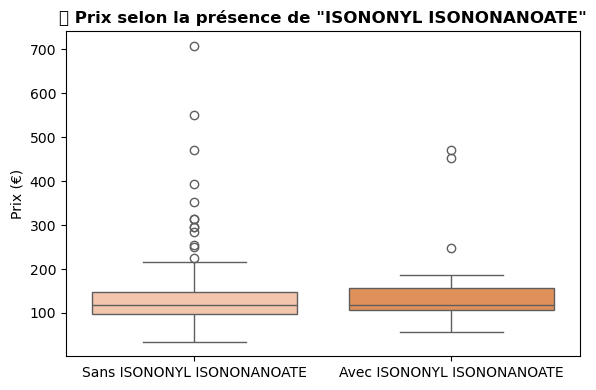


--- Comparaison des prix moyens ---
DIMETHICONE          | Avec : 147.44 € | Sans : 126.46 €
SILICA               | Avec : 147.29 € | Sans : 126.85 €
SYNTHETIC WAX        | Avec : 140.08 € | Sans : 130.15 €
PHENOXYETHANOL       | Avec : 131.21 € | Sans : 133.49 €
CAPRYLIC             | Avec : 149.62 € | Sans : 128.11 €
WATER                | Avec : 119.24 € | Sans : 136.44 €
SYNTHETIC FLUORPHLOGOPITE | Avec : 147.87 € | Sans : 129.23 €
MICA                 | Avec : 146.14 € | Sans : 129.80 €
CAPRYLYL GLYCOL      | Avec : 136.96 € | Sans : 131.98 €
ISONONYL ISONONANOATE | Avec : 140.69 € | Sans : 131.21 €


In [338]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
from collections import Counter

# Étape 1 : Filtrer les produits sans "Non mentionné" dans Ingredients_List
df_filtered = df_face[df_face['Ingredients_List'].apply(lambda x: 'Non mentionné' not in x)]

# Étape 2 : Trouver les 10 ingrédients les plus fréquents
top_ingredients = Counter(itertools.chain.from_iterable(df_filtered['Ingredients_List'])).most_common(10)
top_ingredient_names = [ing[0] for ing in top_ingredients]

# Étape 3 : Ajouter une colonne booléenne pour chaque ingrédient
for ingredient in top_ingredient_names:
    colname = 'Has_' + ingredient.replace(' ', '_').replace('-', '_')
    df_face[colname] = df_face['Ingredients_List'].apply(lambda x: ingredient in x)

# Étape 4 : Visualisation - Boxplots de prix pour chaque ingrédient
for ingredient in top_ingredient_names:
    colname = 'Has_' + ingredient.replace(' ', '_').replace('-', '_')

    plt.figure(figsize=(6, 4))
    sns.boxplot(
        data=df_face,
        x=colname,
        y='Price',
        palette=["#FFC1A1", "#F78C42"]
    )
    plt.title(f'💰 Prix selon la présence de "{ingredient}"', fontsize=12, fontweight='bold')
    plt.xticks([0, 1], [f'Sans {ingredient}', f'Avec {ingredient}'])
    plt.ylabel("Prix (€)")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()

# Étape 5 : Résumé textuel des prix moyens avec/sans l'ingrédient
print("\n--- Comparaison des prix moyens ---")
for ingredient in top_ingredient_names:
    colname = 'Has_' + ingredient.replace(' ', '_').replace('-', '_')
    mean_with = df_face[df_face[colname]]['Price'].mean()
    mean_without = df_face[~df_face[colname]]['Price'].mean()
    print(f"{ingredient:20} | Avec : {mean_with:.2f} € | Sans : {mean_without:.2f} €")


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:37: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:45: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:37: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:45: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:37: FutureWarning:



Passing `palette`

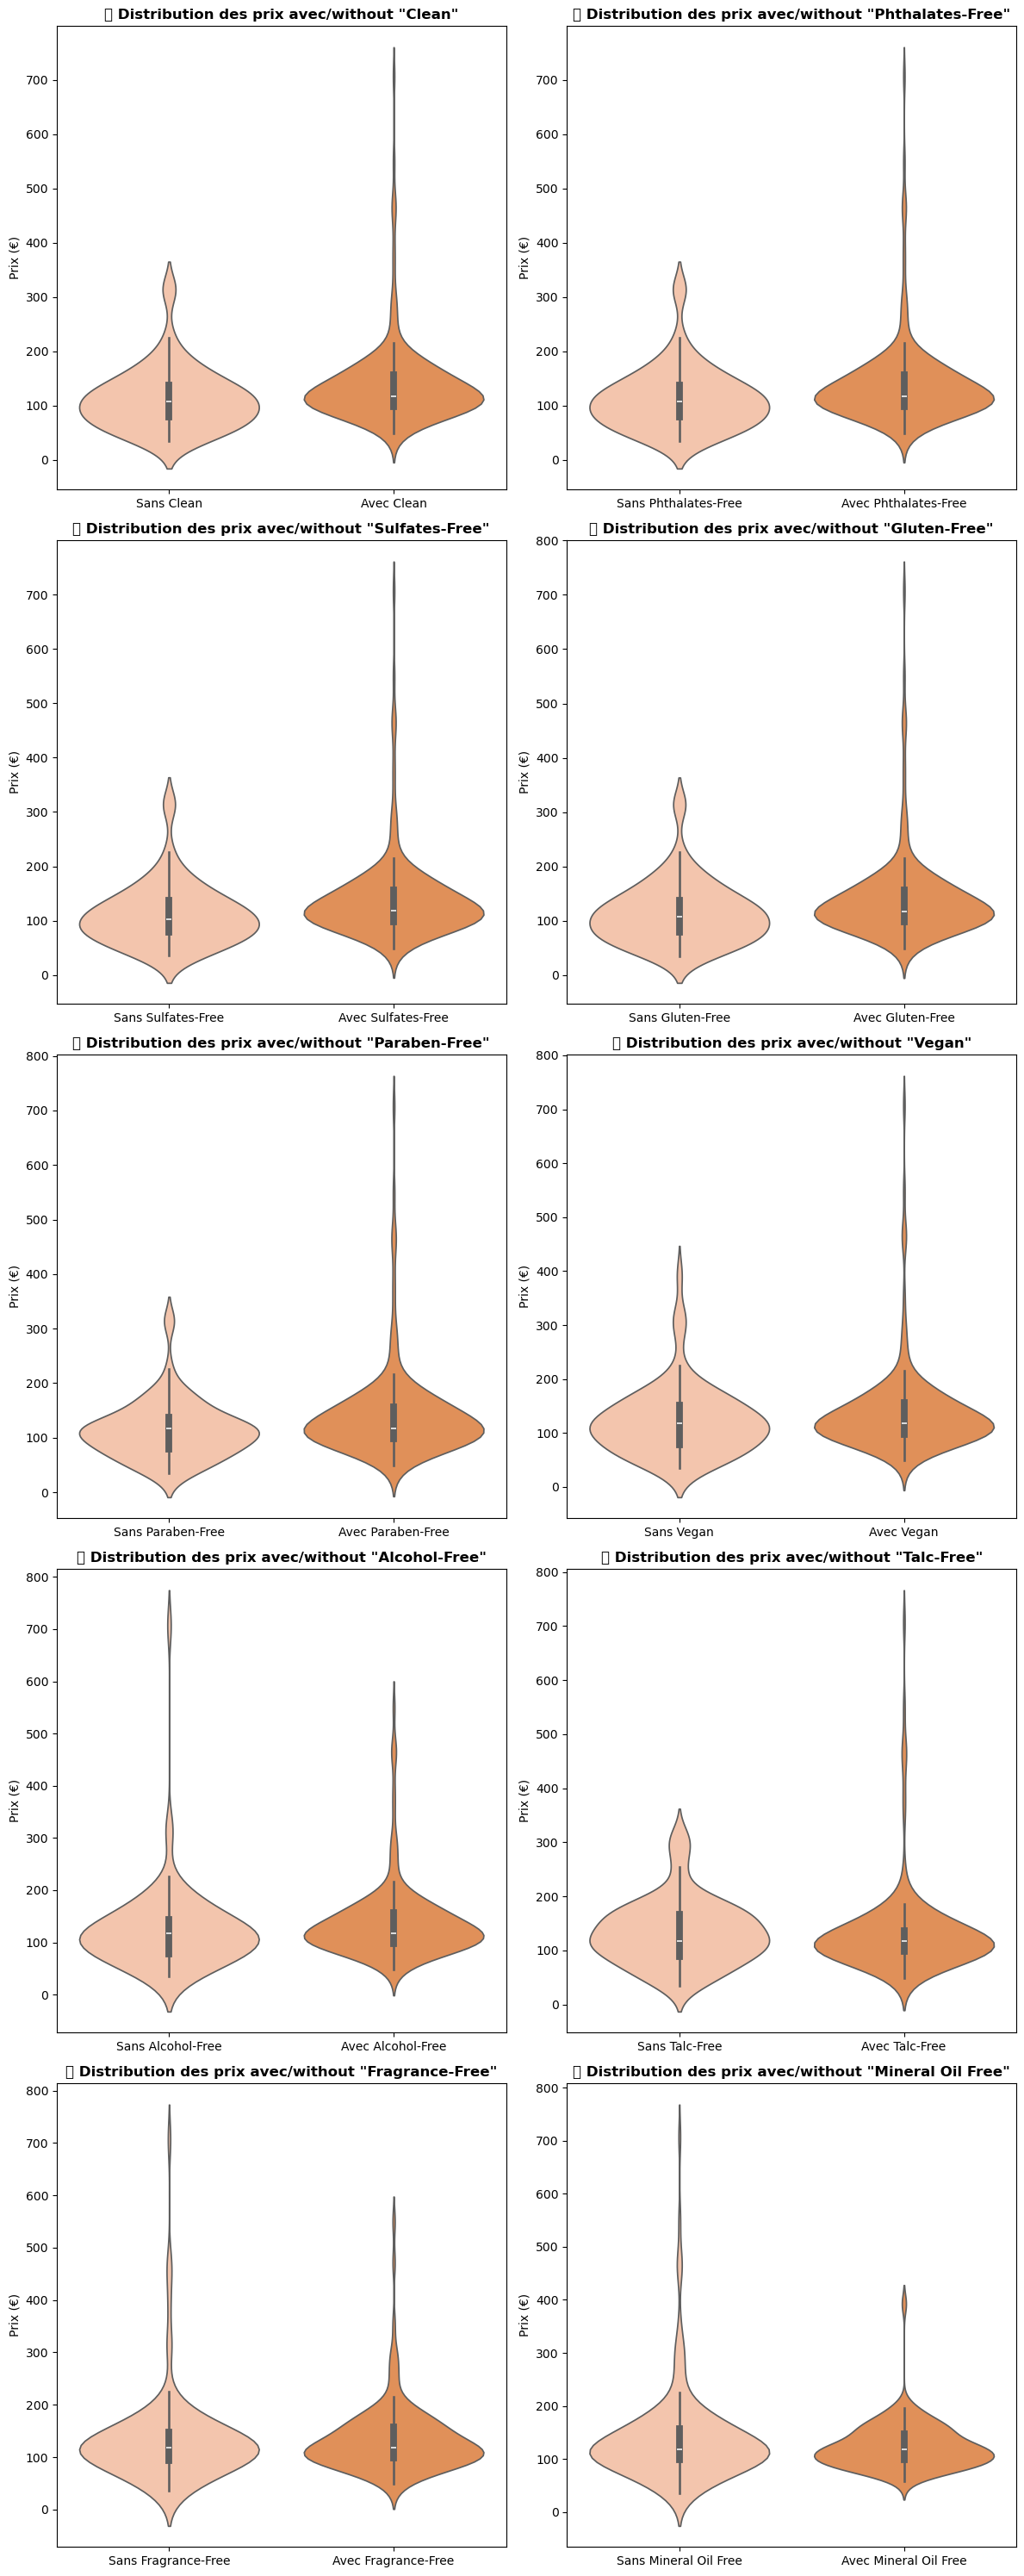

C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:65: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:65: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:65: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\user\AppData\Local\Temp\ipykernel_26676\2765815014.py:65: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same ef

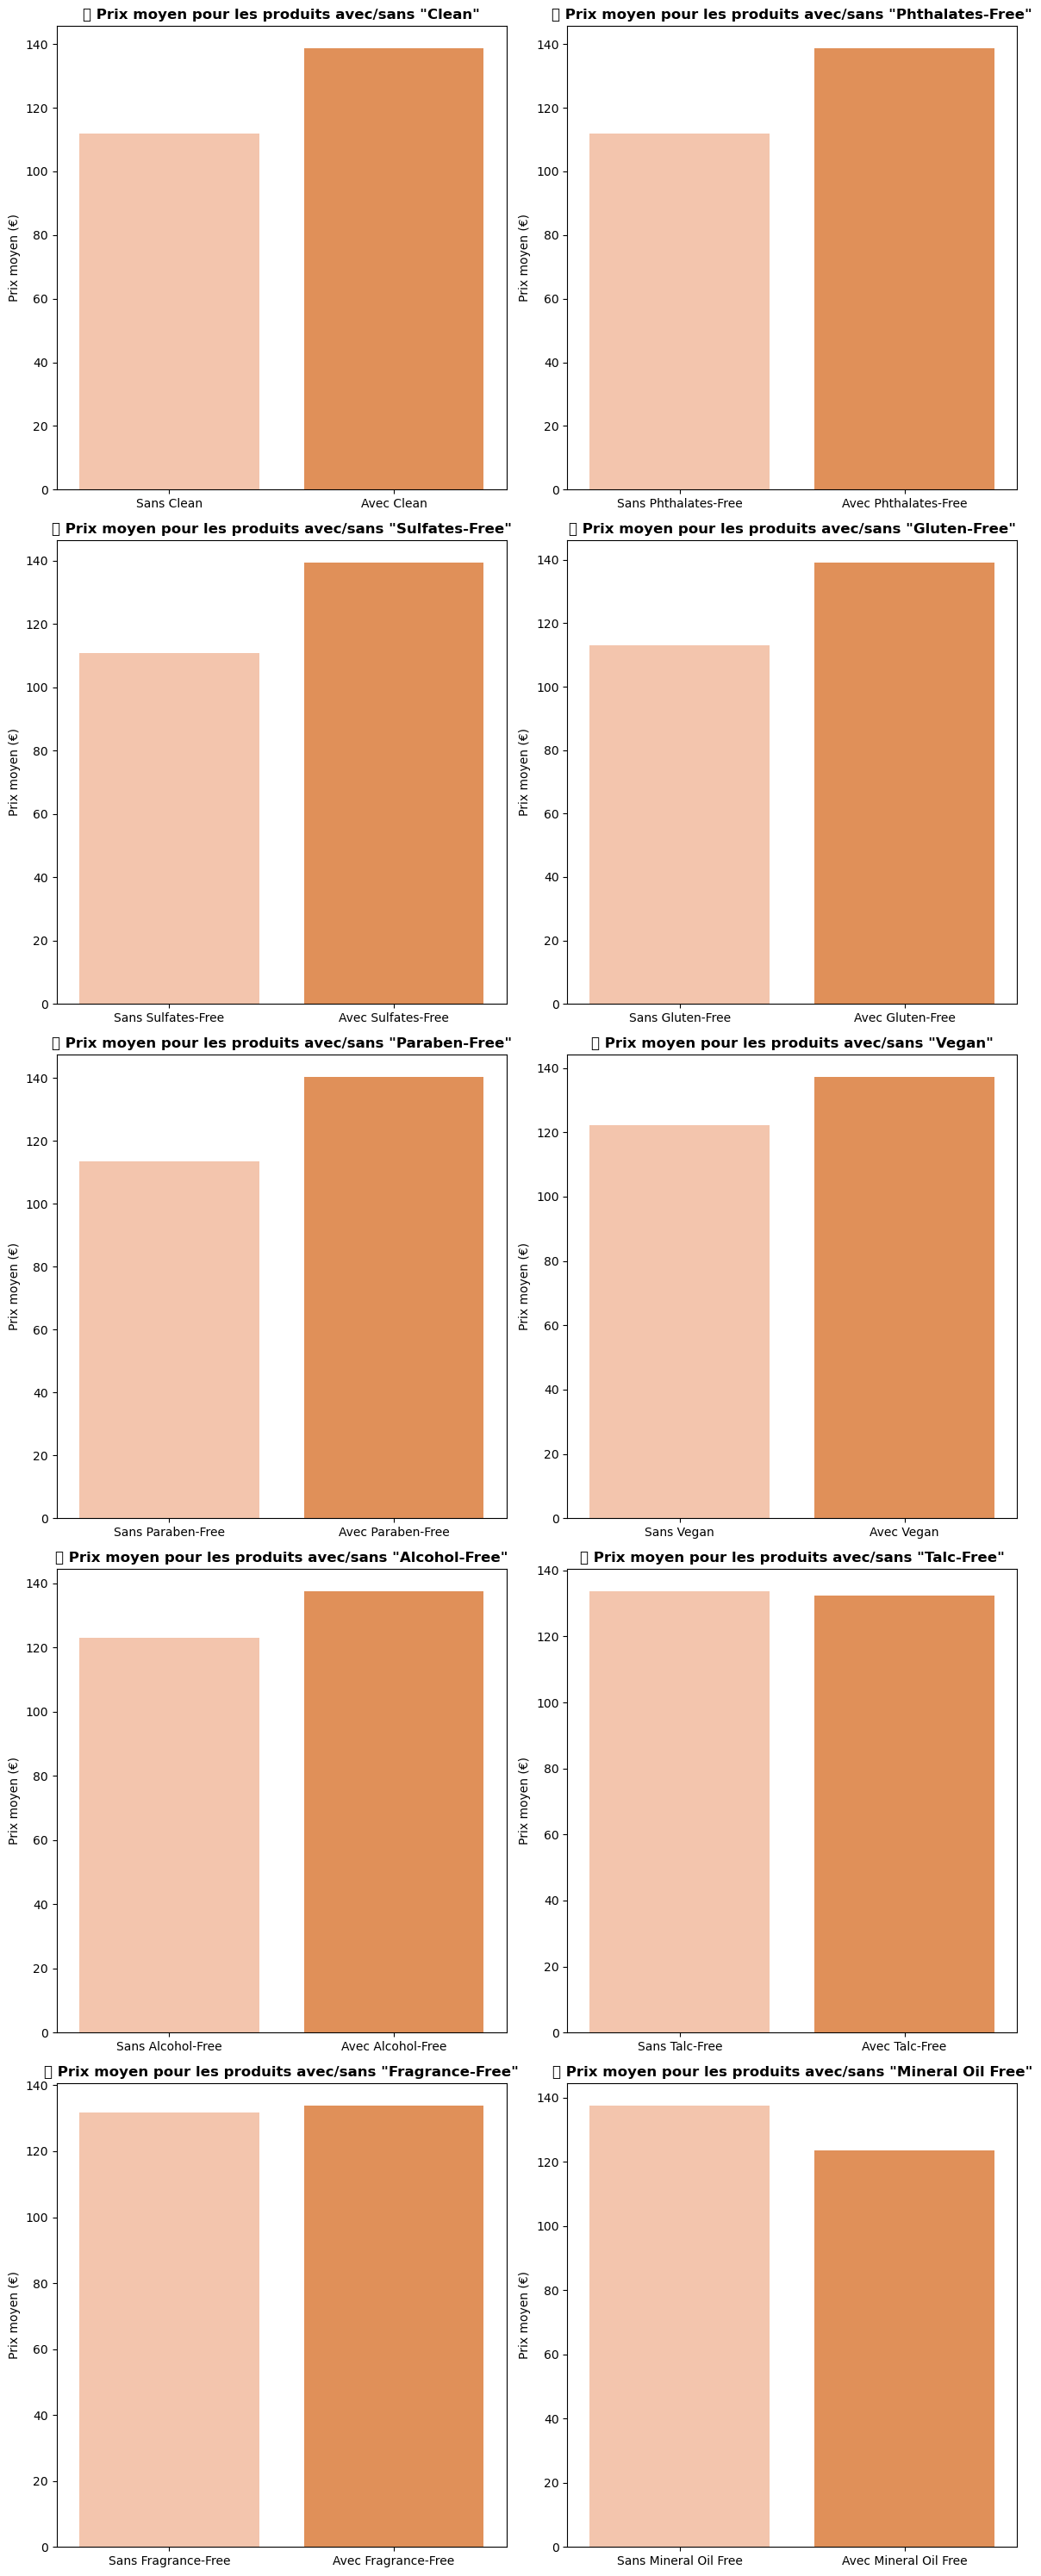


--- Comparaison des prix moyens ---


KeyError: 'Pricen'

In [344]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
from collections import Counter

# Vérification de l'existence de la colonne 'Price_Clean'
if 'Price' not in df_face.columns:
    print("Erreur : La colonne 'Price' n'existe pas dans le DataFrame.")
else:
    # Filtrer les produits sans "Non mentionné" dans Labels_List
    df_filtered = df_face[df_face['Labels_List'].apply(lambda x: 'Non mentionné' not in x)]

    # Trouver les 10 labels les plus fréquents
    top_labels = Counter(itertools.chain.from_iterable(df_filtered['Labels_List'])).most_common(10)
    top_label_names = [label[0] for label in top_labels]

    # Ajouter une colonne booléenne pour chaque label
    for label in top_label_names:
        colname = 'Has_' + label.replace(' ', '_').replace('-', '_')
        df_face[colname] = df_face['Labels_List'].apply(lambda x: label in x)

    # Créer une figure avec des subplots
    n = len(top_label_names)  # Nombre de graphiques
    ncols = 2  # Nombre de colonnes de subplots
    nrows = (n + 1) // ncols  # Nombre de lignes de subplots
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 6 * nrows))

    # Aplatir le tableau des axes si plus de 1 ligne et 1 colonne
    axes = axes.flatten()

    # Étape 1 : Visualisation pour chaque label
    for idx, label in enumerate(top_label_names):
        colname = 'Has_' + label.replace(' ', '_').replace('-', '_')

        # Violin plot sur chaque subplot
        sns.violinplot(
            data=df_face,
            x=colname,
            y='Price',
            palette=["#FFC1A1", "#F78C42"],
            ax=axes[idx]
        )
        axes[idx].set_title(f'💰 Distribution des prix avec/without "{label}"', fontsize=12, fontweight='bold')
        axes[idx].set_xticklabels([f'Sans {label}', f'Avec {label}'])
        axes[idx].set_ylabel("Prix (€)")
        axes[idx].set_xlabel("")

    # Ajuster l'espacement entre les graphiques
    plt.tight_layout()
    plt.show()

    # Étape 2 : Visualisation - Bar Plot pour comparer les prix moyens
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 6 * nrows))
    axes = axes.flatten()

    for idx, label in enumerate(top_label_names):
        colname = 'Has_' + label.replace(' ', '_').replace('-', '_')

        # Calcul des prix moyens
        mean_with = df_face[df_face[colname]]['Price'].mean()
        mean_without = df_face[~df_face[colname]]['Price'].mean()

        # Bar plot sur chaque subplot
        sns.barplot(
            x=[f'Sans {label}', f'Avec {label}'],
            y=[mean_without, mean_with],
            palette=["#FFC1A1", "#F78C42"],
            ax=axes[idx]
        )
        axes[idx].set_title(f'💰 Prix moyen pour les produits avec/sans "{label}"', fontsize=12, fontweight='bold')
        axes[idx].set_ylabel("Prix moyen (€)")
        axes[idx].set_xlabel("")

    # Ajuster l'espacement entre les graphiques
    plt.tight_layout()
    plt.show()

    # Résumé des prix moyens avec/sans chaque label
    print("\n--- Comparaison des prix moyens ---")
    for label in top_label_names:
        colname = 'Has_' + label.replace(' ', '_').replace('-', '_')
        mean_with = df_face[df_face[colname]]['Price'].mean()
        mean_without = df_face[~df_face[colname]]['Pricen'].mean()
        print(f"{label:20} | Avec : {mean_with:.2f} € | Sans : {mean_without:.2f} €")


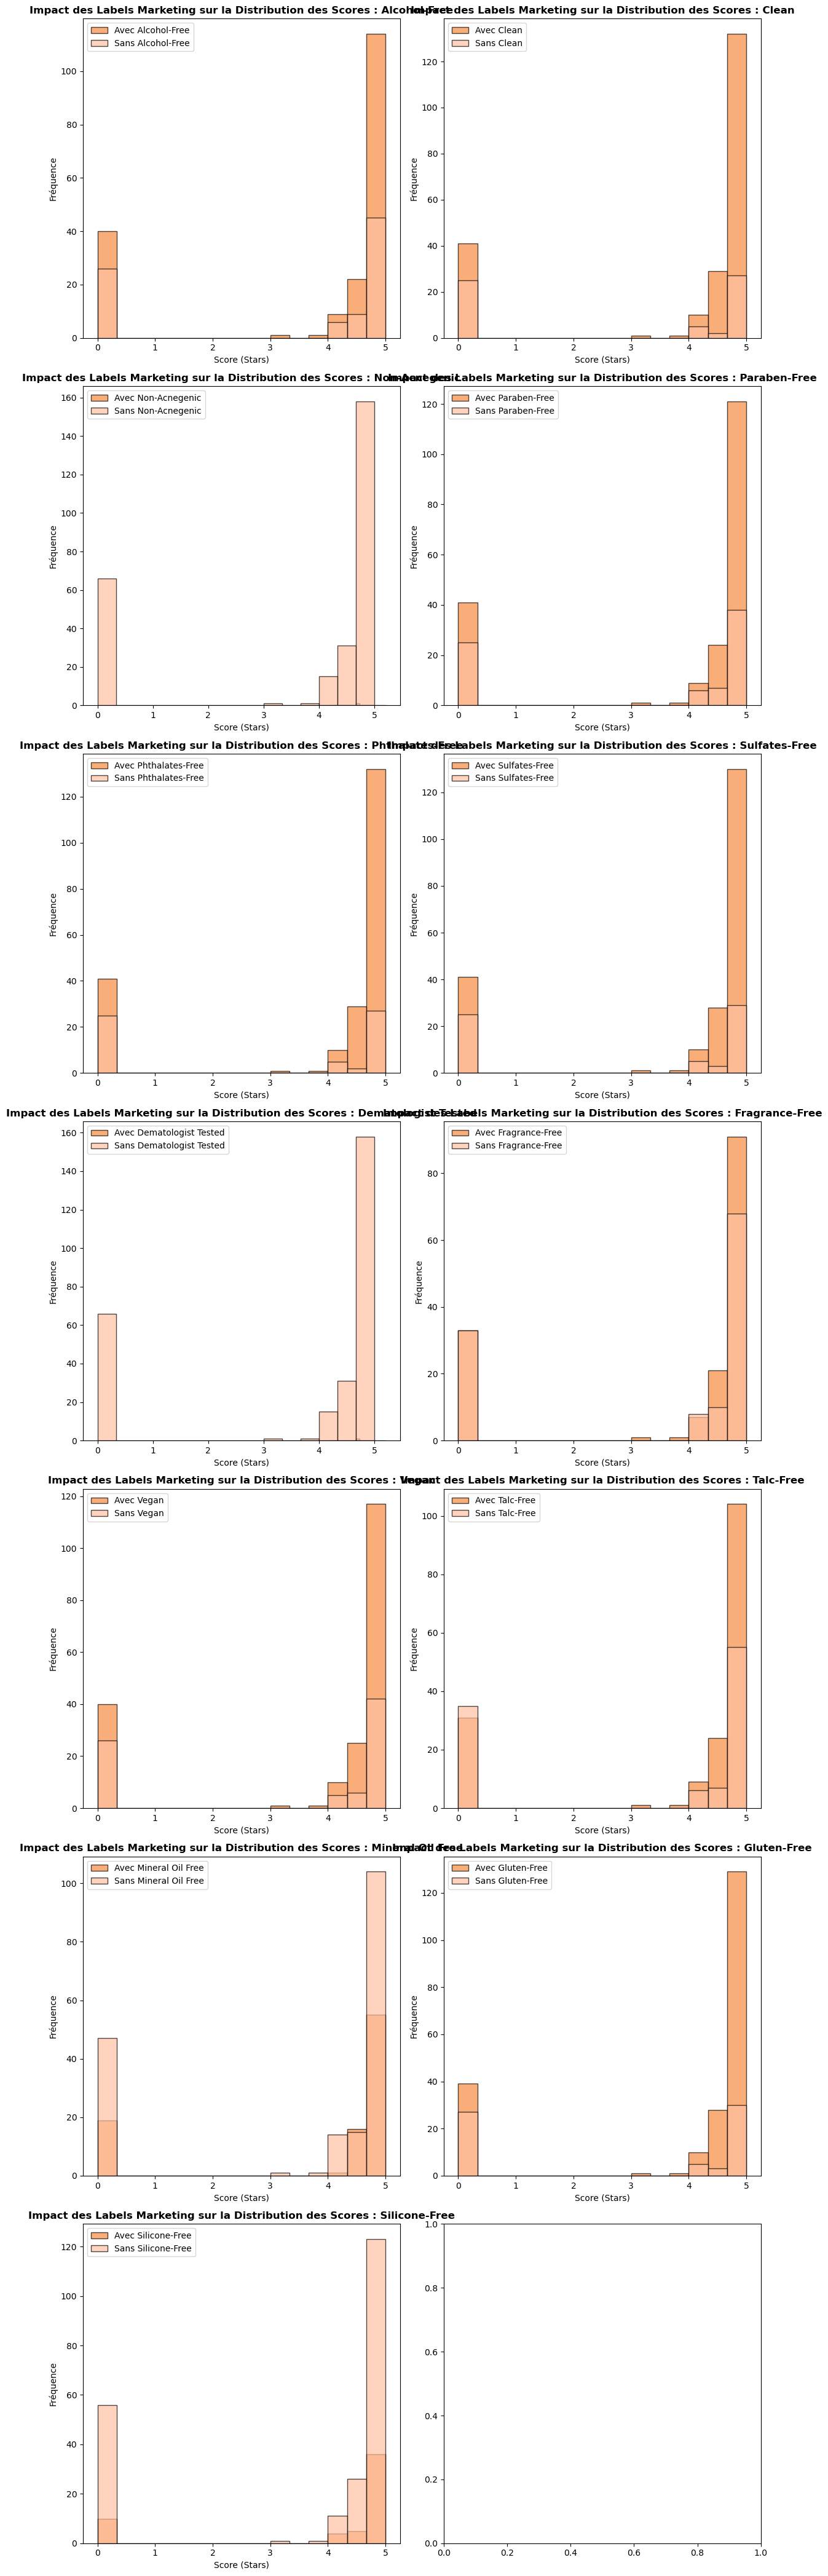

In [346]:
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

# Extraire les labels uniques à partir de la colonne 'Labels_List' (en aplatissant les listes)
all_labels = list(itertools.chain.from_iterable(df_face['Labels_List']))
unique_labels = set(all_labels)  # Extraire les labels uniques

# Fonction pour afficher les histogrammes
def plot_comparison_histograms(df, column_name, values_to_check, title_prefix):
    fig, axes = plt.subplots(nrows=(len(values_to_check) + 1) // 2, ncols=2, figsize=(12, 6 * ((len(values_to_check) + 1) // 2)))
    axes = axes.flatten()

    for idx, value in enumerate(values_to_check):
        colname = f'Has_{column_name}_{value.replace(" ", "_").replace("-", "_")}'
        
        # Créer une colonne booléenne pour la présence du label
        df[colname] = df['Labels_List'].apply(lambda x: value in x)
        
        # Histogramme des scores pour les produits avec et sans ce label
        df_with_label = df[df[colname]]
        df_without_label = df[~df[colname]]
        
        axes[idx].hist(df_with_label['Stars'], bins=15, alpha=0.7, label=f'Avec {value}', color='#F78C42', edgecolor='black')
        axes[idx].hist(df_without_label['Stars'], bins=15, alpha=0.7, label=f'Sans {value}', color='#FFC1A1', edgecolor='black')
        
        axes[idx].set_title(f'{title_prefix} : {value}', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel("Score (Stars)")
        axes[idx].set_ylabel("Fréquence")
        axes[idx].legend()

    # Ajuster l'espacement entre les graphiques
    plt.tight_layout()
    plt.show()

# Étape 1: Comparaison des scores pour tous les labels uniques
plot_comparison_histograms(df_face, 'Label', unique_labels, "Impact des Labels Marketing sur la Distribution des Scores")


C:\Users\user\AppData\Local\Temp\ipykernel_26676\4010405074.py:51: UserWarning:

Glyph 128279 (\N{LINK SYMBOL}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 128279 (\N{LINK SYMBOL}) missing from current font.



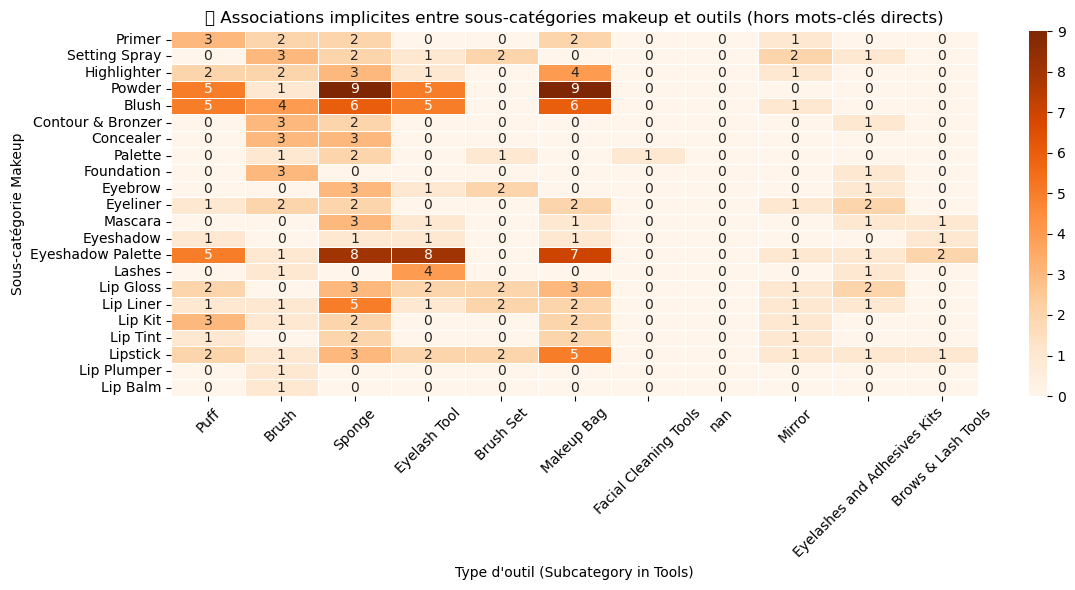

In [352]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
import re

# Nettoyer les noms
def clean_text(text):
    return re.sub(r"[^a-zA-Z]", " ", text).lower()

df_face["Clean_Name"] = df_face["Name"].apply(clean_text)

# Séparer outils et makeup
tools_df = df_face[df_face['Category'] == 'Tools & Others'].copy()
makeup_df = df_face[df_face['Category'] != 'Tools & Others'].copy()

# Mots fréquents par sous-catégorie makeup (hors stop words + mots du nom de la sous-catégorie)
subcategory_keywords = {}
for subcat in makeup_df["Subcategory"].unique():
    names = makeup_df[makeup_df["Subcategory"] == subcat]["Clean_Name"]
    vectorizer = CountVectorizer(stop_words="english", max_features=15)
    X = vectorizer.fit_transform(names)
    words = set(vectorizer.get_feature_names_out())
    
    # Exclure les mots de la sous-catégorie elle-même
    subcat_words = set(clean_text(subcat).split())
    filtered_words = words - subcat_words
    subcategory_keywords[subcat] = filtered_words

# Initialiser tableau des associations
tool_types = tools_df["Subcategory"].unique()
tool_links = pd.DataFrame(0, index=makeup_df["Subcategory"].unique(), columns=tool_types)

# Remplir le tableau : pour chaque outil, voir s’il contient des mots d’une sous-catégorie
for tool_type in tool_types:
    tool_names = tools_df[tools_df["Subcategory"] == tool_type]["Clean_Name"]
    for subcat, keywords in subcategory_keywords.items():
        for tool_name in tool_names:
            for word in keywords:
                if word in tool_name:
                    tool_links.loc[subcat, tool_type] += 1

# Visualisation
plt.figure(figsize=(12, 6))
sns.heatmap(tool_links, annot=True, fmt="d", cmap="Oranges", linewidths=0.5)
plt.title("🔗 Associations implicites entre sous-catégories makeup et outils (hors mots-clés directs)")
plt.xlabel("Type d'outil (Subcategory in Tools)")
plt.ylabel("Sous-catégorie Makeup")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.



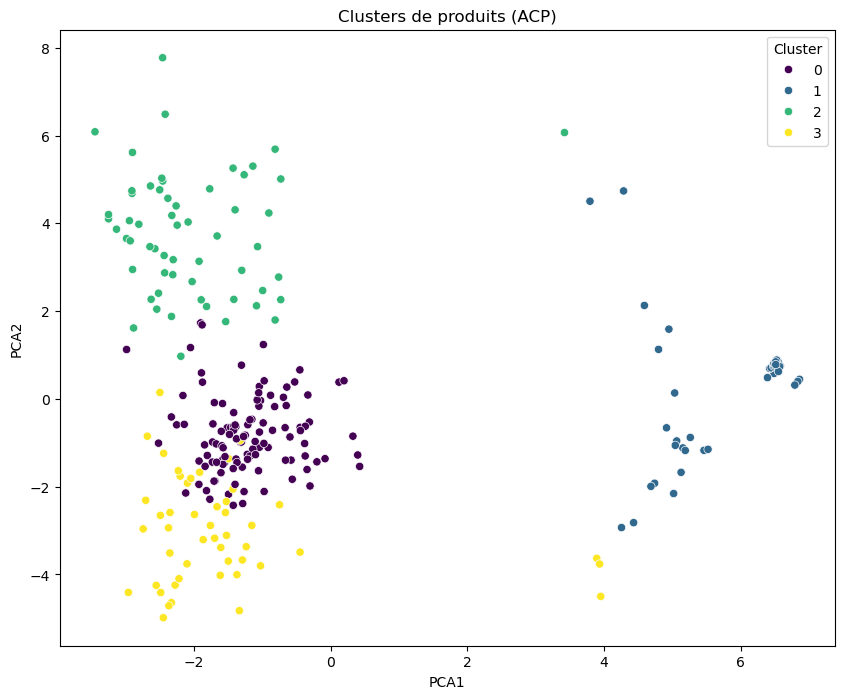

🧪 Ingrédients caractéristiques par cluster :
         Cluster Ing_DIMETHICONE  Cluster Ing_SILICA  \
Cluster                                                
3                       0.875000            0.875000   
2                       0.137931            0.103448   
1                       0.054545            0.127273   
0                       0.276786            0.232143   

         Cluster Ing_SYNTHETIC WAX  Cluster Ing_PHENOXYETHANOL  \
Cluster                                                          
3                         0.416667                    0.583333   
2                         0.034483                    0.500000   
1                         0.163636                    0.072727   
0                         0.401786                    0.071429   

         Cluster Ing_CAPRYLIC  Cluster Ing_WATER  \
Cluster                                            
3                    0.604167           0.020833   
2                    0.017241           0.827586   
1            

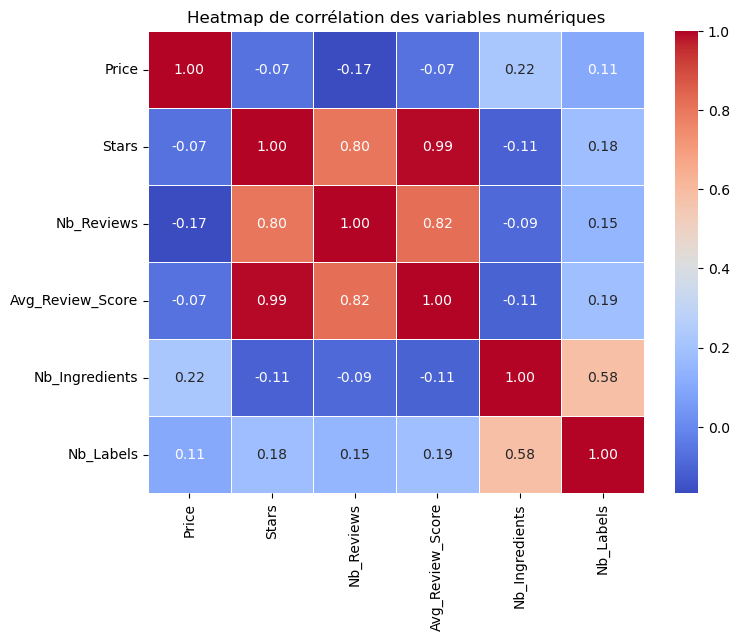

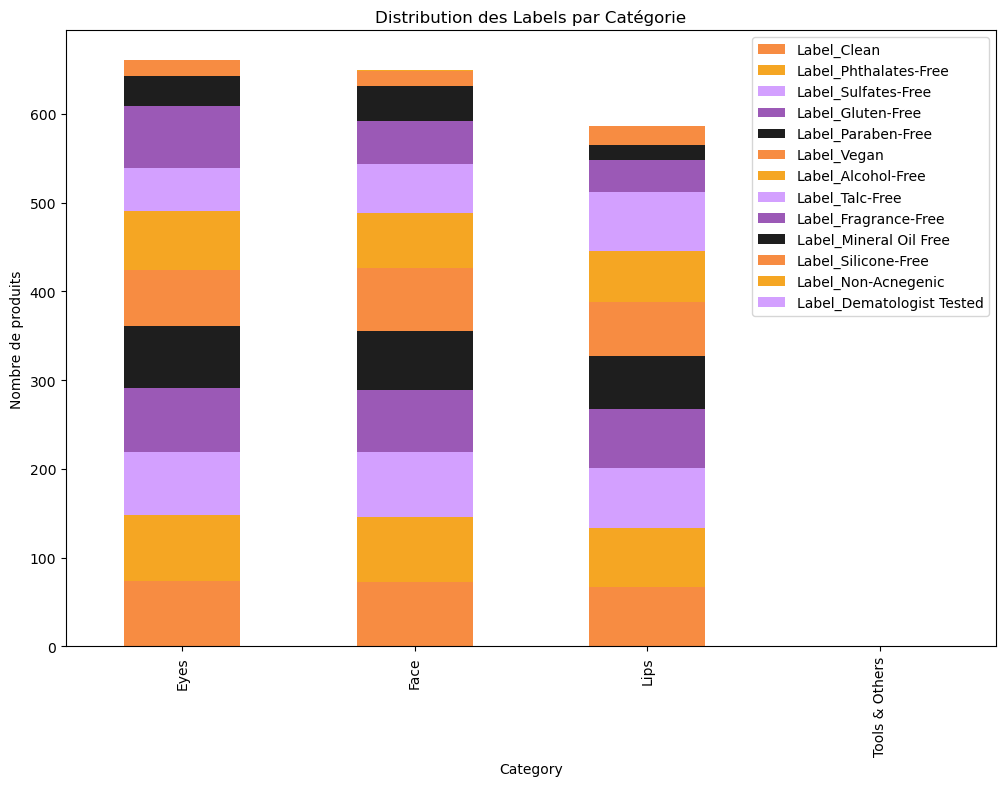

C:\Users\user\AppData\Local\Temp\ipykernel_26676\1101555468.py:106: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

2025-05-13 23:02:53,871 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-13 23:02:53,877 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


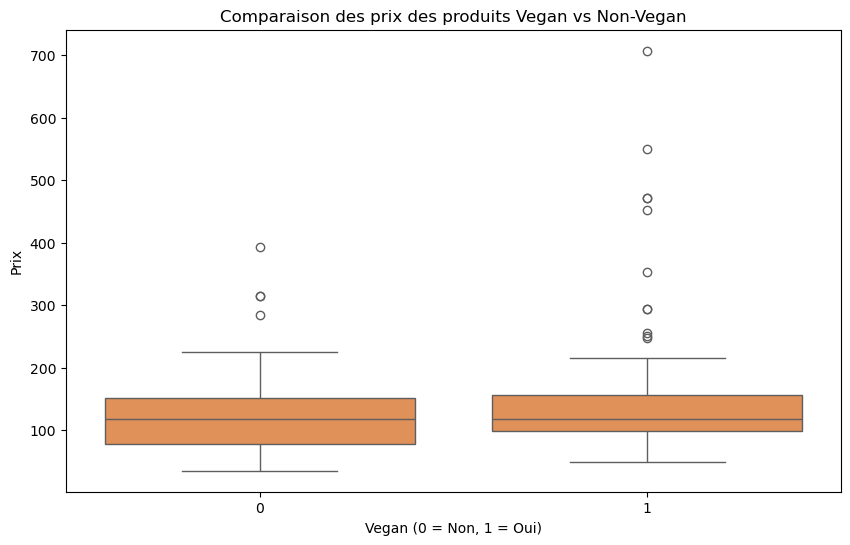

2025-05-13 23:02:53,963 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-13 23:02:53,967 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


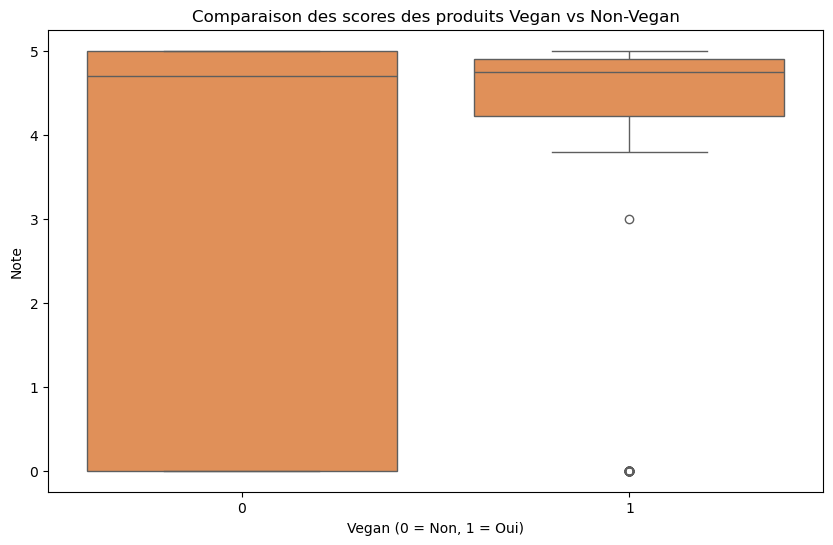

In [372]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA  # Pour la visualisation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Sélectionner les features numériques (après gestion des NaNs)
features_num = df_face[['Price', 'Stars', 'Nb_Reviews', 'Avg_Review_Score']].fillna(0)  # Remplacer les NaNs pour clustering

# Ajouter des features basées sur Ingredients/Labels (exemple: compter le nombre et la présence/absence des tops 50)
df_face['Nb_Ingredients'] = df_face['Ingredients_List'].apply(lambda x: len(x) if x != ["Non mentionné"] else 0)
df_face['Nb_Labels'] = df_face['Labels_List'].apply(lambda x: len(x) if x != ["Non mentionné"] else 0)

# Compter les ingrédients les plus fréquents
ingredient_counts = Counter([ingredient for sublist in df_face['Ingredients_List'] for ingredient in sublist])
top_ingredients = [item[0] for item in ingredient_counts.most_common(50)]
for ingredient in top_ingredients:
    df_face[f'Ing_{ingredient}'] = df_face['Ingredients_List'].apply(lambda x: 1 if ingredient in x else 0)

# Compter les labels les plus fréquents
label_counts = Counter([label for sublist in df_face['Labels_List'] for label in sublist])
top_labels = [item[0] for item in label_counts.most_common(50)]
for label in top_labels:
    df_face[f'Label_{label}'] = df_face['Labels_List'].apply(lambda x: 1 if label in x else 0)

# Créer un DataFrame des ingrédients et labels pour le clustering
features_ingredients_labels = df_face[[f'Ing_{i}' for i in top_ingredients] + [f'Label_{l}' for l in top_labels]]

# Combiner les features numériques, Nb_Ingredients et Nb_Labels, et les features ingrédients/labels
X_cluster = pd.concat([features_num, df_face[['Nb_Ingredients', 'Nb_Labels']], features_ingredients_labels], axis=1)
X_cluster = X_cluster.select_dtypes(include=np.number)  # S'assurer que tout est numérique
X_cluster = X_cluster.fillna(0)  # Remplacer les NaNs restants par 0

# Standardiser les données pour le clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Appliquer K-Means pour le clustering (choisir un nombre de clusters, par exemple 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)  # n_init pour sklearn > 1.0
df_face['Cluster'] = kmeans.fit_predict(X_scaled)  # Ajouter la colonne de cluster assigné

# Réduction de dimension pour la visualisation avec PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_face['PCA1'] = X_pca[:, 0]
df_face['PCA2'] = X_pca[:, 1]

# Visualisation des clusters avec PCA
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_face, x='PCA1', y='PCA2', hue='Cluster', palette='viridis')
plt.title('Clusters de produits (ACP)')
plt.show()

# Analyser les ingrédients caractéristiques par cluster
top_ing_cluster = df_face.groupby('Cluster')[['Ing_' + i for i in top_ingredients]].mean()
top_ing_cluster.columns = [f"Cluster {c}" for c in top_ing_cluster.columns]

# Ajouter une colonne pour l'ingrédient avec la plus grande moyenne pour chaque cluster
top_ing_cluster['Max Cluster'] = top_ing_cluster.idxmax(axis=1)

# Vérifier que nous avons des valeurs numériques pour le calcul du max
# S'assurer que 'Max Value' ne prend que les valeurs numériques
top_ing_cluster['Max Value'] = top_ing_cluster.max(axis=1, numeric_only=True)

# Trier par la valeur maximale et afficher les 10 ingrédients les plus caractéristiques
top_ing_cluster = top_ing_cluster.sort_values(by='Max Value', ascending=False).head(10)

print("🧪 Ingrédients caractéristiques par cluster :")
print(top_ing_cluster)

# Analyser les labels caractéristiques par cluster
top_label_cluster = df_face.groupby('Cluster')[['Label_' + l for l in top_labels]].mean()
top_label_cluster.columns = [f"Cluster {c}" for c in top_label_cluster.columns]

# Ajouter une colonne pour le label avec la plus grande moyenne pour chaque cluster
top_label_cluster['Max Cluster'] = top_label_cluster.idxmax(axis=1)

# Vérifier que nous avons des valeurs numériques pour le calcul du max
# S'assurer que 'Max Value' ne prend que les valeurs numériques
top_label_cluster['Max Value'] = top_label_cluster.max(axis=1, numeric_only=True)

# Trier par la valeur maximale et afficher les 10 labels les plus caractéristiques
top_label_cluster = top_label_cluster.sort_values(by='Max Value', ascending=False).head(10)

print("🧪 Labels caractéristiques par cluster :")
print(top_label_cluster)

# Heatmap de la corrélation entre les variables numériques
corr_matrix = df_face[['Price', 'Stars', 'Nb_Reviews', 'Avg_Review_Score', 'Nb_Ingredients', 'Nb_Labels']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap de corrélation des variables numériques')
plt.show()

# Stacked bar chart pour la distribution des labels les plus fréquents par catégorie
label_counts_per_category = df_face.groupby('Category')[['Label_' + l for l in top_labels]].sum()
label_counts_per_category.plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Distribution des Labels par Catégorie')
plt.ylabel('Nombre de produits')
plt.show()




In [362]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Prédire Prix à partir de Ingredients et Labels (concaténés)
# On crée une seule chaîne pour chaque produit qui contient tous ses ingrédients et labels
df_face['Ingredients_Labels_Str'] = df_face['Ingredients_List'].apply(lambda x: ' '.join(x)) + ' ' + \
                                     df_face['Labels_List'].apply(lambda x: ' '.join(x))
# Enlever "Non mentionné" de cette chaîne si besoin, et mettre en minuscules
df_face['Ingredients_Labels_Str'] = df_face['Ingredients_Labels_Str'].str.replace("Non mentionné", "").str.lower()


X = df_face['Ingredients_Labels_Str']
y_price = df_face['Price'].fillna(df_face['Price'].median()) # Gérer NaNs dans target
y_score = df_face['Avg_Review_Score'].replace(-1, df_face[df_face['Avg_Review_Score'] != -1]['Avg_Review_Score'].mean()) # Gérer la valeur sentinelle pour le score, utiliser la moyenne des scores valides


# Séparer données d'entraînement et de test
X_train, X_test, y_price_train, y_price_test, y_score_train, y_score_test = train_test_split(
    X, y_price, y_score, test_size=0.25, random_state=42
)

# Créer des features numériques avec TF-IDF Vectorizer
# ngram_range=(1,2) pour considérer les paires de mots, min_df pour ignorer les mots très rares
tfidf_vectorizer = TfidfVectorizer(max_features=500, ngram_range=(1,2), min_df=3) # max_features, min_df sont des hyperparamètres à tuner
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Entraîner un modèle pour prédire le PRIX (Régression)
# Utilisez un modèle de régression approprié
model_price = RandomForestRegressor(n_estimators=100, random_state=42)
model_price.fit(X_train_tfidf, y_price_train)
y_price_pred = model_price.predict(X_test_tfidf)

# Évaluer le modèle Prix
print("\nPerformance du modèle de prédiction de PRIX (Random Forest Regression):")
print(f"RMSE: {mean_squared_error(y_price_test, y_price_pred, squared=False):.2f}") # squared=False gives RMSE
print(f"R2 Score: {r2_score(y_price_test, y_price_pred):.2f}")


# Entraîner un modèle pour prédire le SCORE (Régression, ou Classification si vous binez les scores)
# Utilisons la régression ici car le score est continu (moyenne)
model_score = RandomForestRegressor(n_estimators=100, random_state=42)
model_score.fit(X_train_tfidf, y_score_train)
y_score_pred = model_score.predict(X_test_tfidf)
# Clamper les prédictions si elles sortent de l'échelle (0-5)
y_score_pred = np.clip(y_score_pred, 0, 5)

# Évaluer le modèle Score
print("\nPerformance du modèle de prédiction de SCORE (Random Forest Regression):")
print(f"RMSE: {mean_squared_error(y_score_test, y_score_pred, squared=False):.2f}")
print(f"R2 Score: {r2_score(y_score_test, y_score_pred):.2f}")


Performance du modèle de prédiction de PRIX (Random Forest Regression):
RMSE: 114.89
R2 Score: -0.02

Performance du modèle de prédiction de SCORE (Random Forest Regression):
RMSE: 0.00
R2 Score: 1.00


C:\Users\user\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

C:\Users\user\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:483: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.



In [366]:
# Exemple pour le modèle de Prix
feature_names = tfidf_vectorizer.get_feature_names_out()
importances = model_price.feature_importances_
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
print("\nTop 20 features (Ingredients/Labels) les plus importantes pour prédire le PRIX:")
print(feature_importance_df.sort_values('importance', ascending=False).head(20))



Top 20 features (Ingredients/Labels) les plus importantes pour prédire le PRIX:
                       feature  importance
240     isostearyl isostearate    0.065965
357          polyisobutene c15    0.051304
260          malate isostearyl    0.050816
239                 isostearyl    0.043092
34         alkane diisostearyl    0.042911
130                dimethicone    0.040633
238       isostearate isononyl    0.036785
392      silylate hydrogenated    0.028447
409         styrene ethylhexyl    0.026991
416  synthetic fluorphlogopite    0.020408
160            fluorphlogopite    0.019310
443  trimellitate hydrogenated    0.019033
256         magnesium stearate    0.017067
382         silica dimethicone    0.016028
415                  synthetic    0.014816
70                      c15 19    0.014108
167                       free    0.013243
271                       mica    0.012581
418                       talc    0.012532
88                    carbomer    0.012214


              precision    recall  f1-score   support

           0       0.84      0.91      0.87        45
           1       0.33      0.20      0.25        10

    accuracy                           0.78        55
   macro avg       0.59      0.56      0.56        55
weighted avg       0.75      0.78      0.76        55



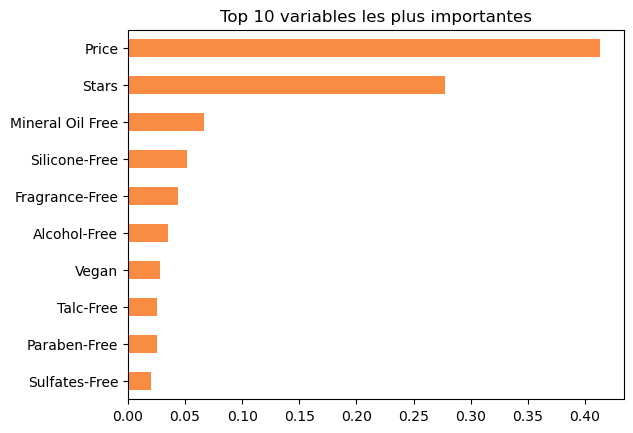

In [374]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report, confusion_matrix

# Nettoyage labels
mlb = MultiLabelBinarizer()
labels_encoded = mlb.fit_transform(df['Labels'].apply(ast.literal_eval))

# Construction X et y
X = pd.concat([
    df_face[['Price', 'Stars']].fillna(0).reset_index(drop=True),
    pd.DataFrame(labels_encoded, columns=mlb.classes_)
], axis=1)

y = df_face['Best Seller']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))
importances = pd.Series(clf.feature_importances_, index=X.columns)
importances.nlargest(10).plot(kind='barh', title="Top 10 variables les plus importantes")
plt.gca().invert_yaxis()
plt.show()

In [417]:

# Définition des bons labels et mauvais ingrédients
good_labels = ['vegan', 'cruelty-free', 'alcohol-free', 'paraben-free', 'fragrance-free']
bad_ingredients = ['alcohol', 'paraben', 'fragrance']

# Fonction de scoring
def score_product(row):
    # Score des labels (présents dans la liste des bons labels)
    label_score = sum(label.lower() in [l.lower() for l in row['Labels_List']] for label in good_labels)
    
    # Pénalité pour mauvais ingrédients
    ingredient_penalty = sum(bad.lower() in [i.lower() for i in row['Ingredients_List']] for bad in bad_ingredients)
    
    # Bonus pour être best seller
    bestseller_bonus = 2 if row['Best Seller'] == 1 else 0

    # Score global (ajuster les poids selon vos priorités)
    return (
        label_score * 2              # Bonus pour bons labels
        - ingredient_penalty * 1.5   # Pénalité pour mauvais ingrédients
        + row['Avg_Review_Score'] * 1.2
        + (row['Nb_Reviews'] / 100)  # Popularité
        + bestseller_bonus           # Bonus Best Seller
    )

# Application du score
df_face['Product_Score'] = df_face.apply(score_product, axis=1)

# Pour éviter le warning de fragmentation
df_face = df_face.copy()

# Sélection du meilleur produit de chaque catégorie
best_per_category = df_face.loc[df_face.groupby('Review_Text_Summary')['Product_Score'].idxmax()]

# Affichage du panier
panier_ideal = best_per_category[
    ['Review_Text_Summary', 'Name', 'Avg_Review_Score', 'Nb_Reviews', 'Best Seller', 'Product_Score', 'Labels_List', 'Ingredients_List']
]

print(panier_ideal)


            Review_Text_Summary  \
85   1 reviews, score moyen 0.0   
104  2 reviews, score moyen 0.0   
132  3 reviews, score moyen 0.0   
88   4 reviews, score moyen 0.0   
0    5 reviews, score moyen 0.0   
84                 Aucun review   

                                                  Name  Avg_Review_Score  \
85                            Pro-Flex Angled Eyeliner               0.0   
104  Harry Potter™ X SHEGLAM Monster Book Of Monste...               0.0   
132                                Hi Brow Shaping Wax               0.0   
88                     Flutter Wink Volumizing Mascara               0.0   
0                                  Pore No More Primer               0.0   
84                      Streamline Brow & Eyeliner Gel              -1.0   

     Nb_Reviews  Best Seller  Product_Score  \
85            1            1          10.01   
104           2            1          10.02   
132           3            0           8.03   
88            4            1     

C:\Users\user\AppData\Local\Temp\ipykernel_26676\134751707.py:8: UserWarning:

Glyph 129351 (\N{FIRST PLACE MEDAL}) missing from current font.

C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

Glyph 129351 (\N{FIRST PLACE MEDAL}) missing from current font.



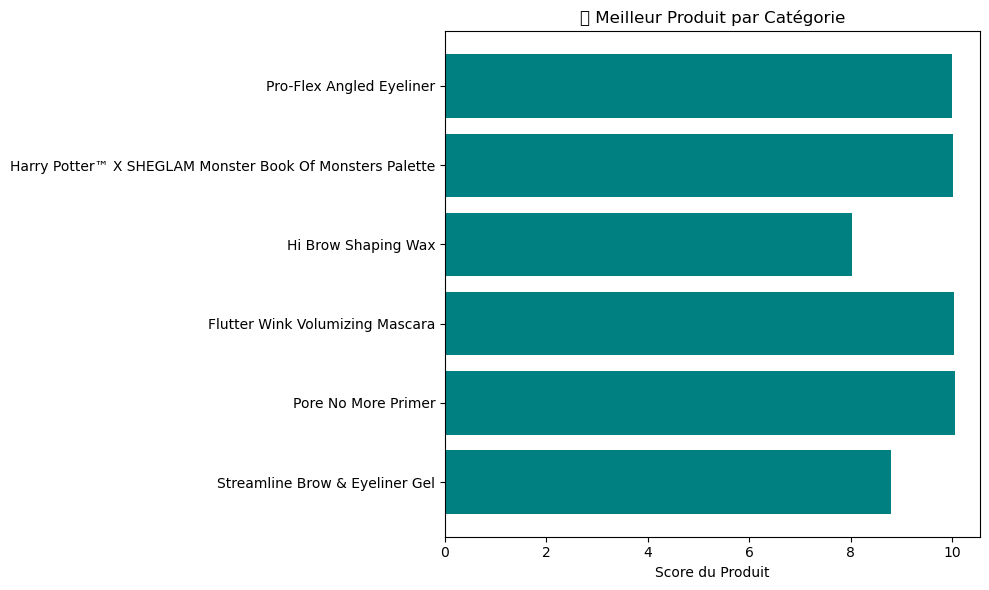

In [423]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(panier_ideal['Name'], panier_ideal['Product_Score'], color='teal')
plt.xlabel('Score du Produit')
plt.title('🥇 Meilleur Produit par Catégorie')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



In [467]:
# display price and stars statistics
df_hair[['Price','Stars']].describe().round(2)


,Price,Stars
count,23.00,23.00
mean,142.00,3.44
std,33.22,2.33
min,58.73,0.00
25%,117.66,0.00
50%,147.12,5.00
75%,161.85,5.00
max,196.23,5.00


In [471]:

df_hair.groupby('Category')[['Price','Stars']].mean().round(2)
df_hair.groupby('Subcategory')[['Price', 'Stars']].mean().round(2).sort_values('Price', ascending=False)


,Price,Stars
Subcategory,,
Hair Straightener Iron,196.23,5.00
Curling Tongs & Curling Wands,150.40,4.98
Hot-Air Brushes & Straight Hair Combs,143.85,3.25
Hair Treatment,139.76,2.45
Hair Coloring,117.66,0.00
Styling Products,117.66,0.00


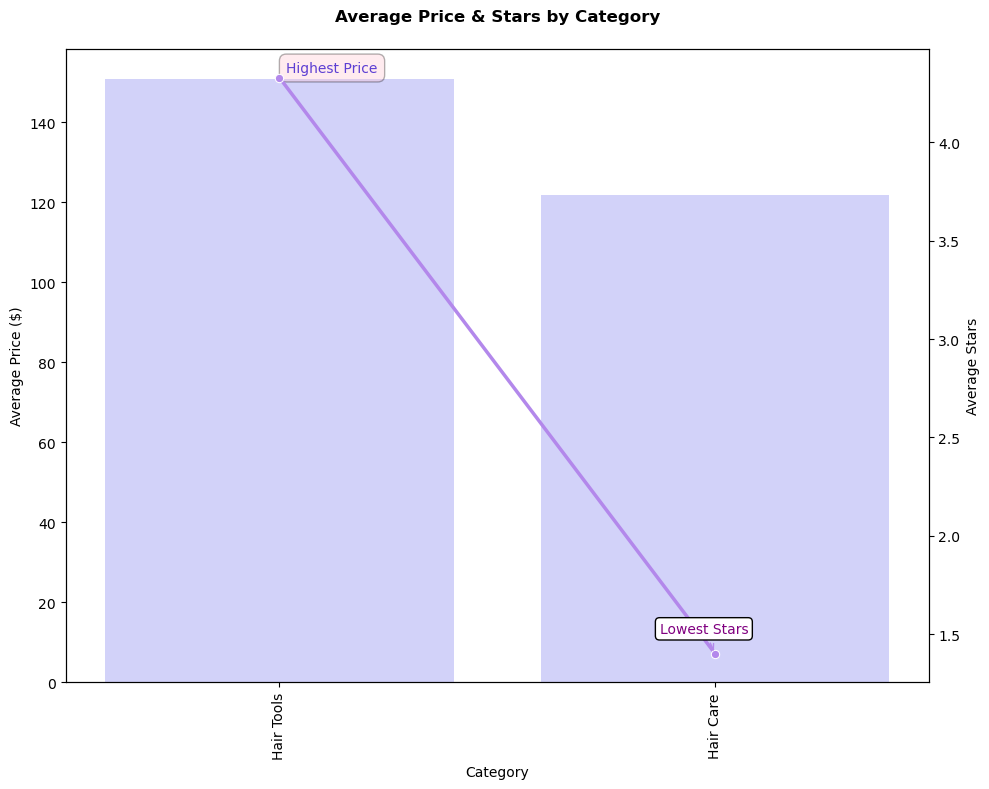

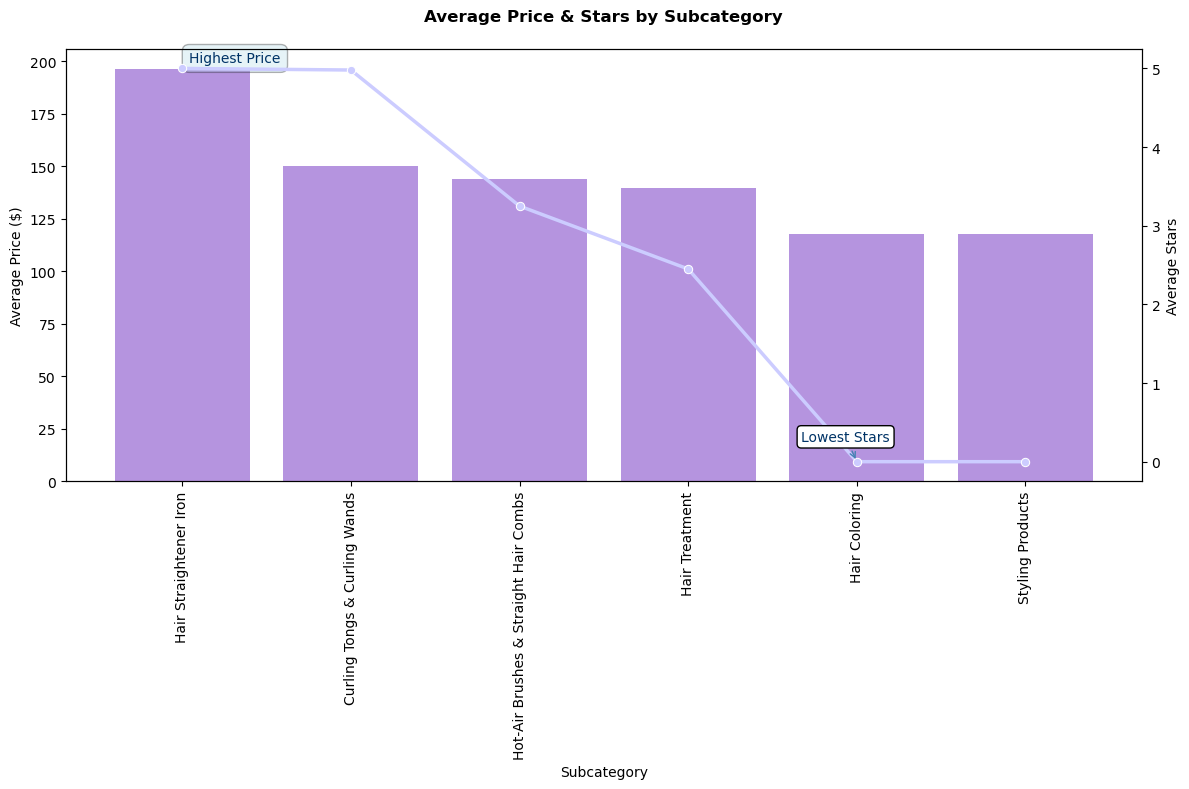

In [473]:
# see the average price/stars in every category
df_hair.groupby('Category')[['Price','Stars']].mean().round(2)
# Prepare data
subcat_stats = df_hair.groupby('Category')[['Price','Stars']].mean().round(2).sort_values('Price', ascending=False)
plt.figure(figsize=(10,8))
ax = sns.barplot(x=subcat_stats.index, y='Price', data=subcat_stats, color='#CCCCFF')  
plt.xticks(rotation=90)
plt.ylabel('Average Price ($)')
plt.title('Average Price & Stars by Category', pad=20, color='black', fontweight='bold')
ax2 = ax.twinx()
sns.lineplot(x=subcat_stats.index, y='Stars', data=subcat_stats,
             color='#B388EB', marker='o', ax=ax2, linewidth=2.5)  
ax2.set_ylabel('Average Stars')
# Highlight key findings with cuter styles
ax.annotate('Highest Price', xy=(0, subcat_stats.Price.iloc[0]),
            xytext=(5, 5), textcoords='offset points',
            bbox=dict(boxstyle='round,pad=0.5', fc='#FFC0CB', alpha=0.3),
            color='#5D3FD3')
ax2.annotate('Lowest Stars', xy=(subcat_stats.Stars.idxmin(), subcat_stats.Stars.min()),
             xytext=(-40, 15), textcoords='offset points',
             arrowprops=dict(arrowstyle='->', color='#B388EB'),
             bbox=dict(boxstyle='round', fc='white'),
             color='#800080')  # Purple
plt.tight_layout()
plt.show()

# Average price/stars per Subcategory
subcat_stats = df_hair.groupby('Subcategory')[['Price', 'Stars']].mean().round(2).sort_values('Price', ascending=False)
plt.figure(figsize=(12, 8))
ax = sns.barplot(x=subcat_stats.index, y='Price', data=subcat_stats, color='#B388EB')  
plt.xticks(rotation=90)
plt.ylabel('Average Price ($)')
plt.title('Average Price & Stars by Subcategory', pad=20, color='black', fontweight='bold')
ax2 = ax.twinx()
sns.lineplot(x=subcat_stats.index, y='Stars', data=subcat_stats,
             color='#CCCCFF', marker='o', ax=ax2, linewidth=2.5)  
ax2.set_ylabel('Average Stars')
ax.annotate('Highest Price', xy=(0, subcat_stats.Price.iloc[0]),
            xytext=(5, 5), textcoords='offset points',
            bbox=dict(boxstyle='round,pad=0.5', fc='#ADD8E6', alpha=0.3),  
            color='#003366')

ax2.annotate('Lowest Stars', xy=(subcat_stats.Stars.idxmin(), subcat_stats.Stars.min()),
             xytext=(-40, 15), textcoords='offset points',
             arrowprops=dict(arrowstyle='->', color='#4682B4'),
             bbox=dict(boxstyle='round', fc='white'),
             color='#003366') 
plt.tight_layout()
plt.show()


          Price     Stars
Price  1.000000  0.528396
Stars  0.528396  1.000000


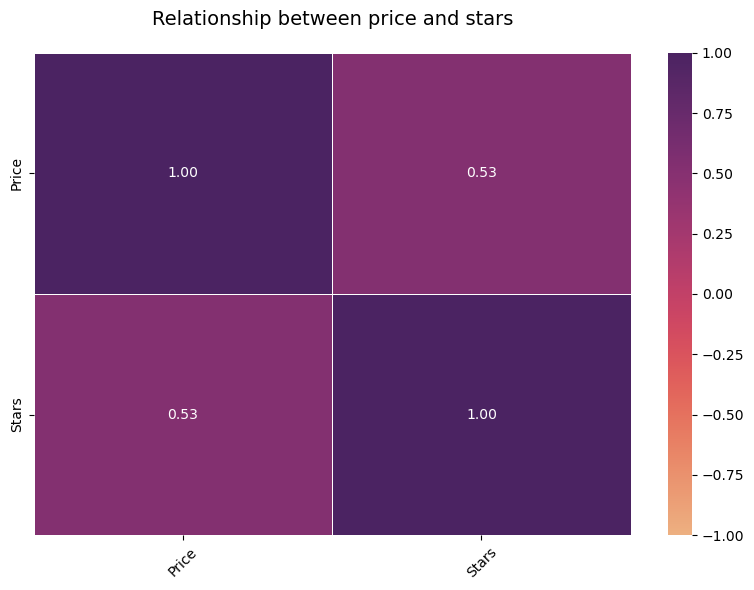

In [475]:
# check if there is a relationship between the price and the stars of the product
print(df_hair[['Price', 'Stars']].corr())
plt.figure(figsize=(8, 6))
sns.heatmap(df_hair[['Price', 'Stars']].corr(),annot=True,cmap='flare',vmin=-1,vmax=1,linewidths=0.5,fmt=".2f")
plt.title("Relationship between price and stars", fontsize=14, pad=20)
plt.xticks(rotation=45) 
plt.tight_layout()     
plt.show()

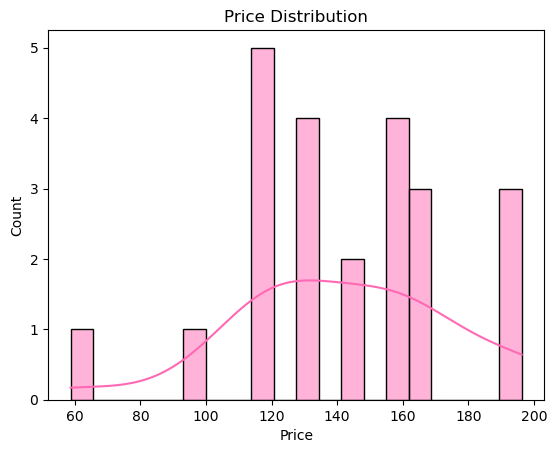

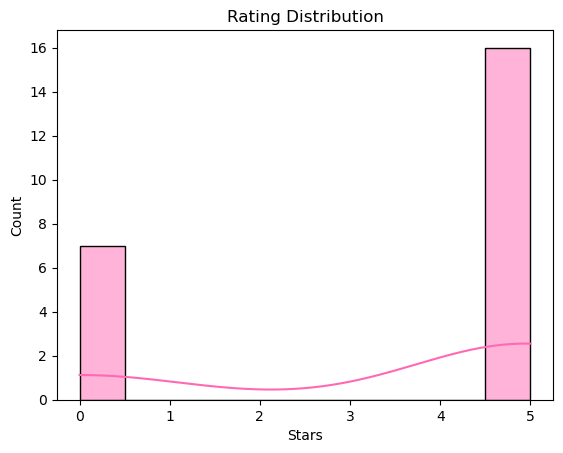

In [477]:
# the Price Distribution tells us that most products on the site are budget-friendly
sns.histplot(df_hair['Price'], bins=20, kde=True,color='hotpink')
plt.title('Price Distribution')
plt.show()
# the Rating Distribution shows that most products have high rating
sns.histplot(df_hair['Stars'], bins=10, kde=True,color='hotpink')
plt.title('Rating Distribution')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_26676\3878503529.py:7: UserWarning:

The palette list has more values (6) than needed (2), which may not be intended.



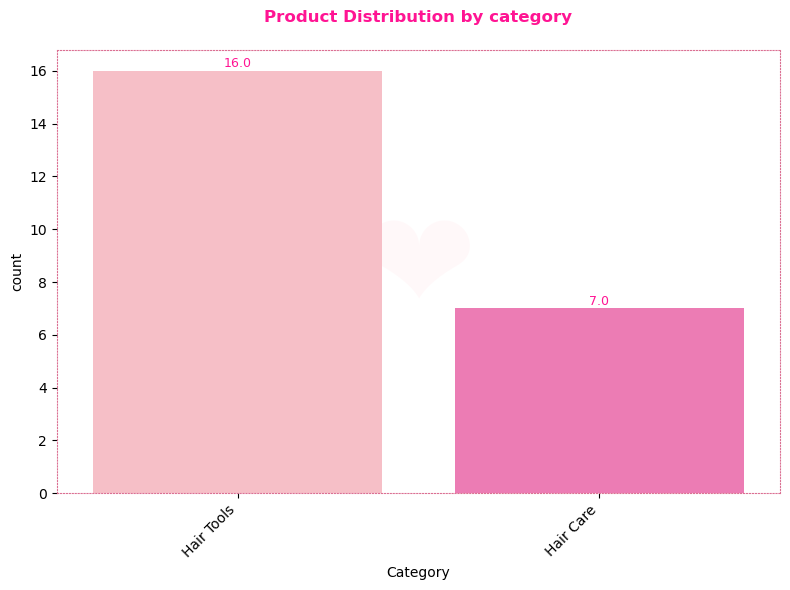

In [489]:
# count the number of products in each category
# Set available fonts
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial Unicode MS']
# Create figure with white background
plt.figure(figsize=(8,6))
ax = sns.countplot(x='Category', data=df_hair,order=df_hair['Category'].value_counts().index,hue='Category',
                  palette=['#FFB6C1', '#FF69B4', '#FF1493',
                          '#DB7093', '#FFC0CB', '#FF85C7'],legend=False)
# Set white background (only change made)
ax.set_facecolor('white')
plt.gcf().set_facecolor('white')
# Keep original pink dotted borders
for spine in ax.spines.values():
    spine.set_linestyle(':')
    spine.set_color('#DB7093')  
    #spine.set_linewidth(1.5)
# Keep original pink heart watermark
heart = plt.Text(0.5, 0.5, '❤',fontsize=100,color='pink',alpha=0.1,ha='center',va='center',transform=ax.transAxes)
ax.add_artist(heart)
plt.xticks(rotation=45, ha='right')
plt.title('Product Distribution by category',
          fontsize=12, pad=20, color='#FF1493', fontweight='bold')
for p in ax.patches:
    ax.annotate(f'{p.get_height()}',
               (p.get_x() + p.get_width()/2., p.get_height()),ha='center', va='center',xytext=(0, 5),
               textcoords='offset points',
               color='#FF1493',
               fontsize=9)
plt.tight_layout()
plt.show()

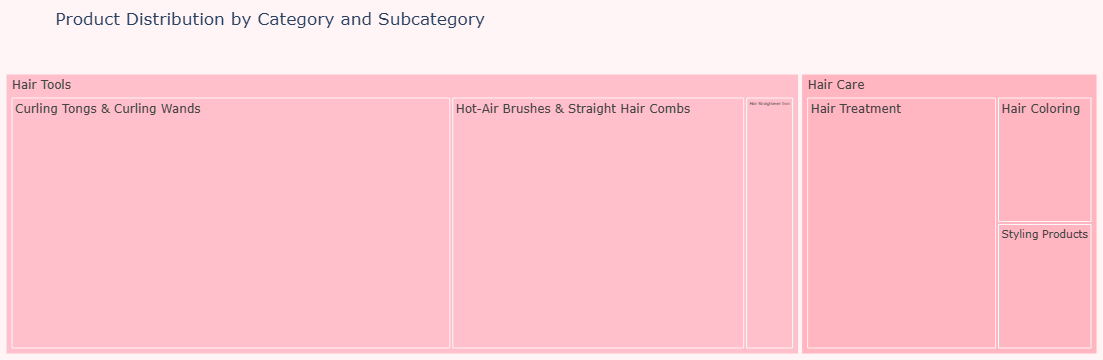

In [497]:
import plotly.express as px
df_hair = df_hair.dropna(subset=['Category', 'Subcategory'])
# Create the treemap with custom category colors
pink_palette = [
    "#FFC0CB",  # Pink
    "#FFB6C1",  # Light Pink
    "#FF69B4",  # Hot Pink
    "#DB7093",  # Pale Violet Red
    "#FF1493",  # Deep Pink
    "#E75480",  # Dark Pink
    "#FFA6C9",  # Pastel Pink
    "#F4C2C2",  # Baby Pink
]
# Get unique categories
categories = df_hair['Category'].unique()
# Create the color map
color_map = {category: pink_palette[i % len(pink_palette)] for i, category in enumerate(categories)}
fig = px.treemap(
    df_hair,
    path=['Category', 'Subcategory'],
    title='Product Distribution by Category and Subcategory',
    color='Category',
    color_discrete_map=color_map
)
# Simple styling
fig.update_layout(
    paper_bgcolor='#FFF5F7',  
    margin=dict(t=50, l=0, r=0, b=0))
fig.show()

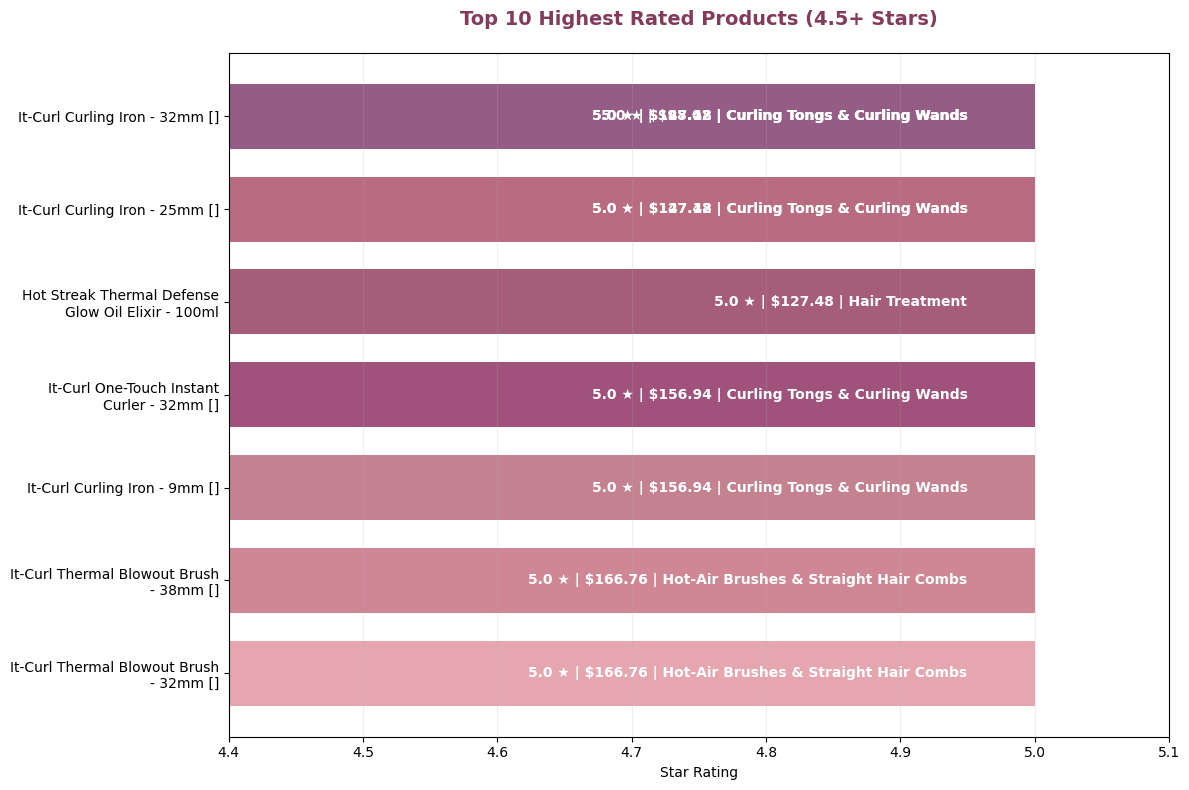

In [501]:
# Top 10 rated products
top_rated = df_hair[df_hair['Stars'] >= 4.5].sort_values(by=['Stars', 'Price'], ascending=[False, True]).head(10)
plt.figure(figsize=(12, 8))
girly_shades = [
    '#D36C6C',  # Dusty rose
    '#C97A9E',  # Blush mauve
    '#B36A5E',  # Terracotta pink
    '#A55D79',  # Rosewood
    '#955D85',  # Mauve
    '#B96B82',  # Soft berry
    '#A0527D',  # Plum pink
    '#C48291',  # Warm pink
    '#D08795',  # Faded red
    '#E6A6B0'   # Rose quartz
]
bars = plt.barh(
    top_rated['Name'].str.wrap(30),
    top_rated['Stars'],
    color=girly_shades[:len(top_rated)],
    height=0.7)
for bar, price, category in zip(bars, top_rated['Price'], top_rated['Subcategory']):
    width = bar.get_width()
    plt.text(
        width - 0.05,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f} ★ | ${price} | {category}",
        va='center',
        ha='right',
        color='white',
        fontweight='bold')
plt.title('Top 10 Highest Rated Products (4.5+ Stars)', pad=20, fontsize=14, fontweight='bold', color='#833A5B')
plt.xlabel('Star Rating')
plt.xlim(4.4, 5.1)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

📉 Mean Squared Error (MSE): 859.89
📈 R² Score: -0.36
💰 Prix prédit pour Shampoo noté 4.5 : 148.02


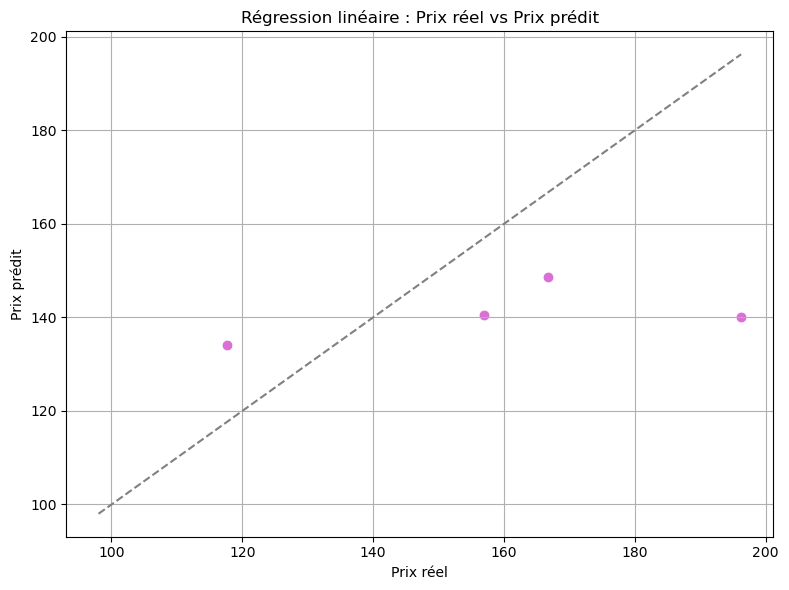

C:\Users\user\AppData\Local\Temp\ipykernel_26676\2568261887.py:101: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




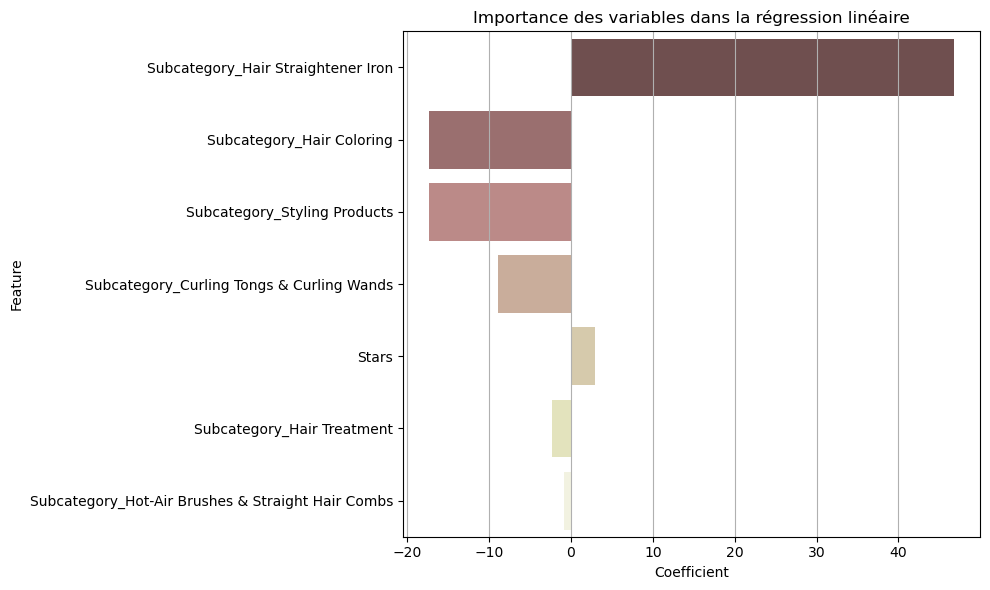

In [507]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# -------------------------------
# 1. Nettoyage des données
# -------------------------------
df_hair = df_hair.dropna(subset=['Price', 'Stars', 'Subcategory'])
df_hair = df_hair.reset_index(drop=True)

# -------------------------------
# 2. Variables d’entrée et cible
# -------------------------------
X = df_hair[['Stars', 'Subcategory']]
y = df_hair['Price']

# -------------------------------
# 3. Pipeline : encodage + modèle
# -------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Subcategory'])
    ],
    remainder='passthrough'  # conserve 'Stars'
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# -------------------------------
# 4. Split données
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# -------------------------------
# 5. Entraînement
# -------------------------------
model.fit(X_train, y_train)

# -------------------------------
# 6. Prédiction et évaluation
# -------------------------------
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"📉 Mean Squared Error (MSE): {mse:.2f}")
print(f"📈 R² Score: {r2:.2f}")

# -------------------------------
# 7. Prédiction d'un exemple
# -------------------------------
example = pd.DataFrame({'Stars': [4.5], 'Subcategory': ['Shampoo']})
predicted_price = model.predict(example)
print(f"💰 Prix prédit pour Shampoo noté 4.5 : {predicted_price[0]:.2f}")

# -------------------------------
# 8. Visualisation : Réel vs Prédit
# -------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, color="orchid", s=60)
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--', color='gray')
plt.xlabel("Prix réel")
plt.ylabel("Prix prédit")
plt.title("Régression linéaire : Prix réel vs Prix prédit")
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# 9. Visualisation : Coefficients
# -------------------------------
# Obtenir les noms de features (encodés + 'Stars')
encoded_names = model.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out(['Subcategory'])
feature_names = list(encoded_names) + ['Stars']

coefficients = model.named_steps['regressor'].coef_

# Vérification des dimensions
assert len(feature_names) == len(coefficients), "Erreur de longueur : noms vs coefficients"

# Création du DataFrame des coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', key=abs, ascending=False)

# Graphique des coefficients
plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='pink')
plt.title("Importance des variables dans la régression linéaire")
plt.grid(axis='x')
plt.tight_layout()
plt.show()
